# Library Import

Pandas
Importing the data into a dataframe; for manipulations of the dataframe and easy plotting

Numpy
For vector and matrix calculations

Matplotlib
For plotting

Seaborn
For plotting

SKLearn
For the machine learning part

Scipy
For some statistics


In [4]:
pip install matplotlib pandas seaborn scikit-learn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.8.0-cp314-cp314-macosx_12_0_arm64.whl.metadata (11 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached scikit_learn-1.8.0-cp314-cp314-macosx_12_0_arm64.whl (8.1 MB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 6.6 MB/s  0:00:03m 6.9 MB/s eta 0:00:01m
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [seaborn]━━━ 4/5 [seaborn]earn]
Note: you may need to restart the kernel to use updated packages.


# Importing libraries

In [37]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colorbar as mpl

from sklearn.model_selection import train_test_split
from mpl_toolkits.axes_grid1 import make_axes_locatable
from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFECV
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from collections import Counter
from numpy import where
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline



# Data Import

In [2]:
data = pd.read_csv("data.csv", na_filter=False, skipinitialspace=True, thousands=',')
print(data.head())

   sweep_id  pdb_id_id  wavelength  MR_success   TFZ     LLG  PAK  mr_reso  \
0       732       1019      0.9763         0.0   0.0    55.0  4.0     2.16   
1      1158       1025      0.9792         1.0  61.2  2449.0  0.0     1.70   
2      1159       1025      0.9184         1.0  61.2  2449.0  0.0     1.70   
3      1160       1025      0.9788         1.0  61.2  2449.0  0.0     1.70   
4       997        103      0.9253         0.0   9.5    57.0  0.0     2.50   

  mr_sg  mr_sg_no  ...  wilsonbfactor  RmeasI  highreslimit  RpimdiffI  \
0    P1         1  ...          33.66  0.1056          2.16     0.5707   
1   H32       155  ...          19.62  0.1414          1.70     0.0706   
2   H32       155  ...          21.20  0.1563          1.75     0.0790   
3   H32       155  ...          18.88  0.1491          1.93     0.0809   
4    P1         1  ...          -8.45  0.2506          1.87     0.1343   

  anomalousmulti  RmergediffI  totalobservations  anomalouscompl  cchalf  \
0         

In [3]:
print(data.shape)

(663, 38)


# Isolate column names to use as features

In [4]:
column_names = data.columns
print(column_names)

Index(['sweep_id', 'pdb_id_id', 'wavelength', 'MR_success', 'TFZ', 'LLG',
       'PAK', 'mr_reso', 'mr_sg', 'mr_sg_no', 'RMSD', 'VRMS', 'eLLG', 'tncs',
       'model_pdb', 'seq_ident', 'model_res', 'anomalousCC', 'IoverSigma',
       'completeness', 'diffI', 'RmergeI', 'lowreslimit', 'RpimI',
       'multiplicity', 'RmeasdiffI', 'anomalousslope', 'diffF',
       'wilsonbfactor', 'RmeasI', 'highreslimit', 'RpimdiffI',
       'anomalousmulti', 'RmergediffI', 'totalobservations', 'anomalouscompl',
       'cchalf', 'totalunique'],
      dtype='str')


In [5]:
data_columns = data[['wavelength', 'TFZ', 'LLG', 'PAK', 'mr_reso',
       'mr_sg_no', 'RMSD', 'VRMS', 'eLLG', 'tncs', 'seq_ident',
       'model_res', 'anomalousCC', 'IoverSigma', 'completeness', 'diffI',
       'RmergeI', 'lowreslimit', 'RpimI', 'multiplicity', 'RmeasdiffI',
       'anomalousslope', 'diffF', 'wilsonbfactor', 'RmeasI', 'highreslimit',
       'RpimdiffI', 'anomalousmulti', 'RmergediffI', 'totalobservations',
       'anomalouscompl', 'cchalf', 'totalunique']]

data_columns_labels = data_columns.columns
print(data_columns_labels)

Index(['wavelength', 'TFZ', 'LLG', 'PAK', 'mr_reso', 'mr_sg_no', 'RMSD',
       'VRMS', 'eLLG', 'tncs', 'seq_ident', 'model_res', 'anomalousCC',
       'IoverSigma', 'completeness', 'diffI', 'RmergeI', 'lowreslimit',
       'RpimI', 'multiplicity', 'RmeasdiffI', 'anomalousslope', 'diffF',
       'wilsonbfactor', 'RmeasI', 'highreslimit', 'RpimdiffI',
       'anomalousmulti', 'RmergediffI', 'totalobservations', 'anomalouscompl',
       'cchalf', 'totalunique'],
      dtype='str')


# Fill in missing values

In [6]:
data_columns_fill = data_columns.fillna(0)

# Data split - test and training set 

In [7]:
y = data['MR_success']

X_train, X_test, y_train, y_test = train_test_split(data_columns_fill, y, 
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Plot histogram for each feature

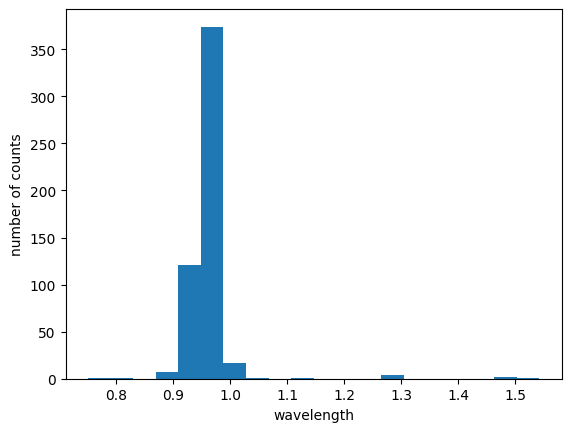

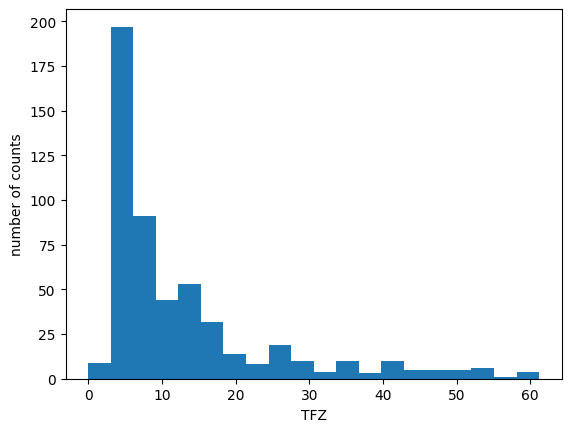

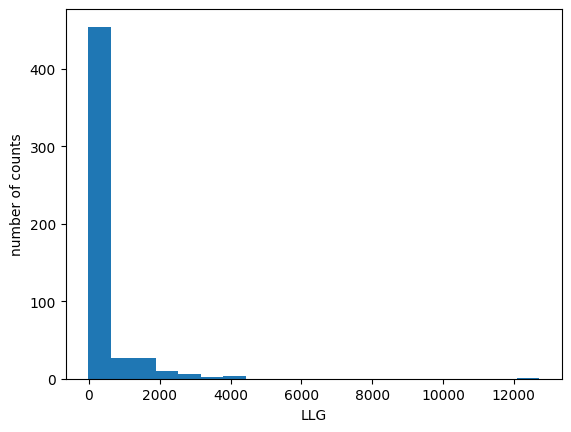

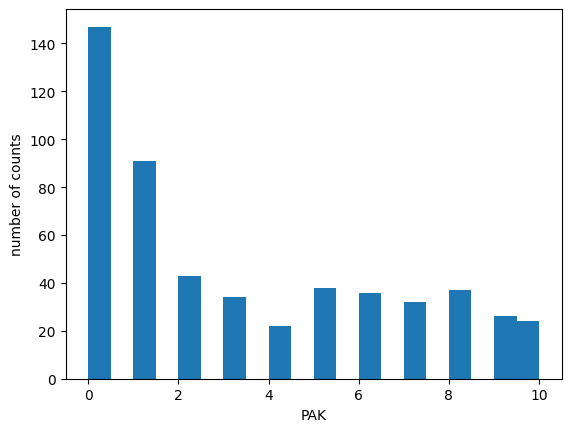

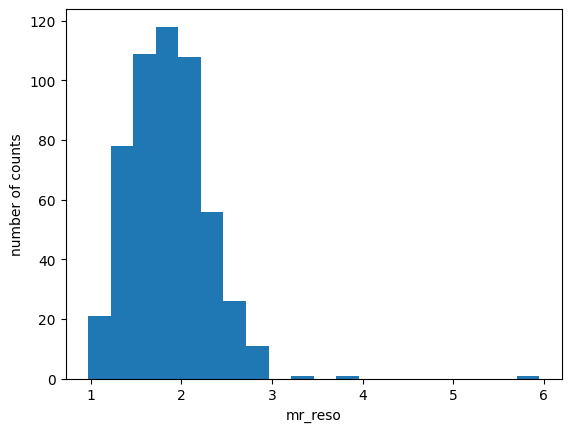

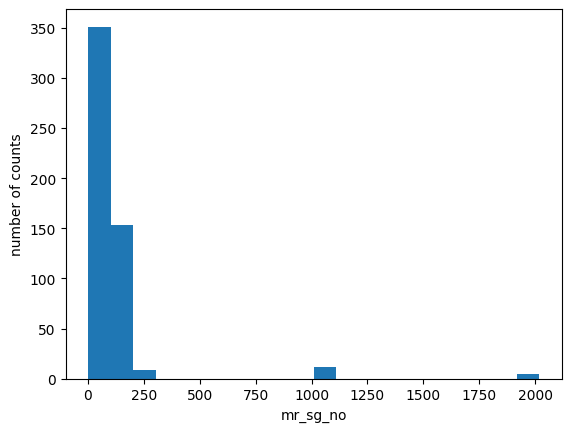

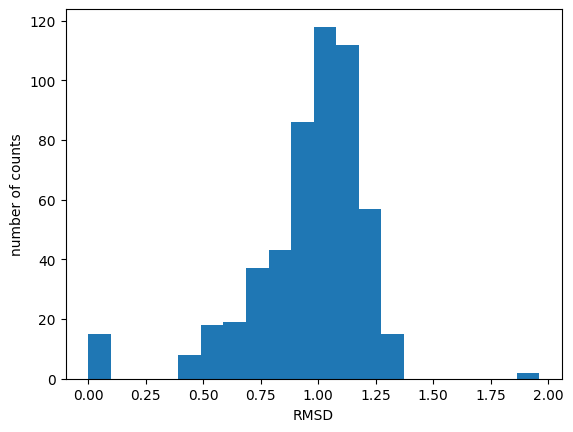

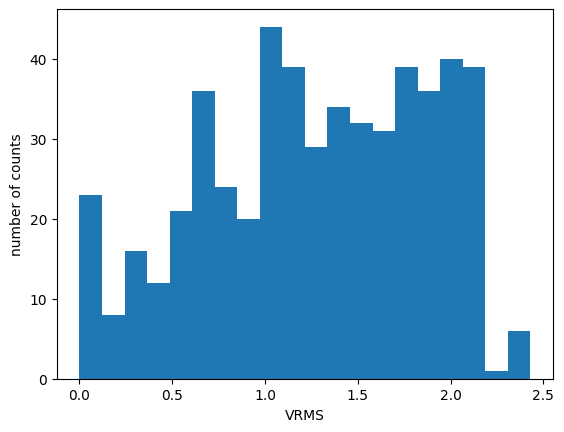

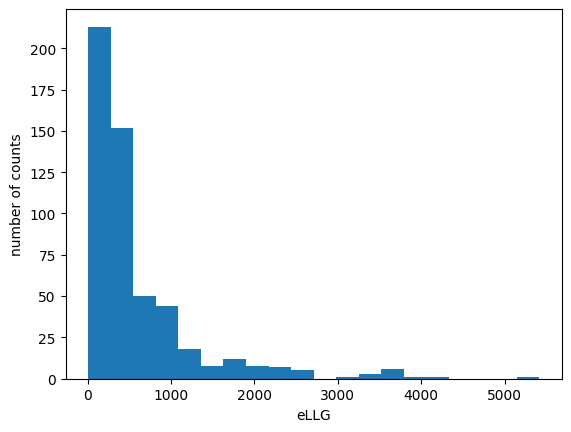

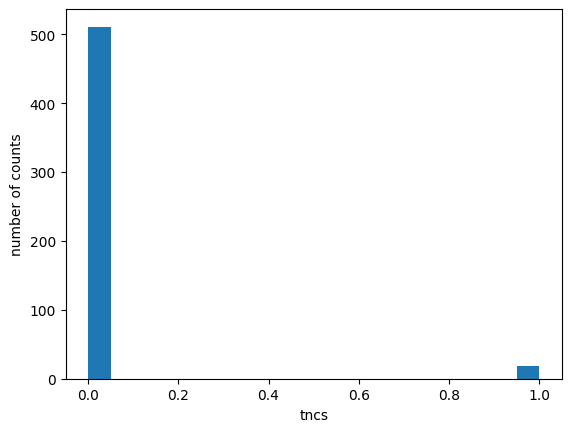

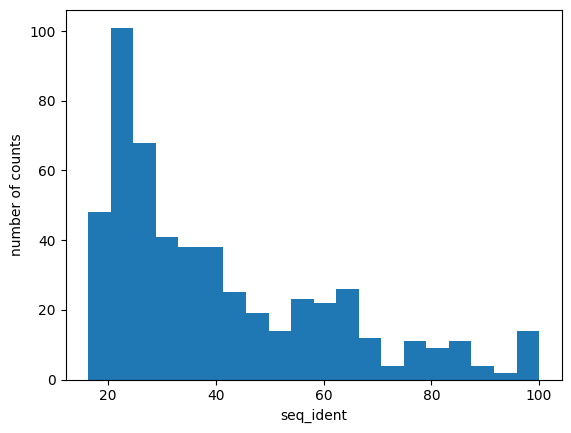

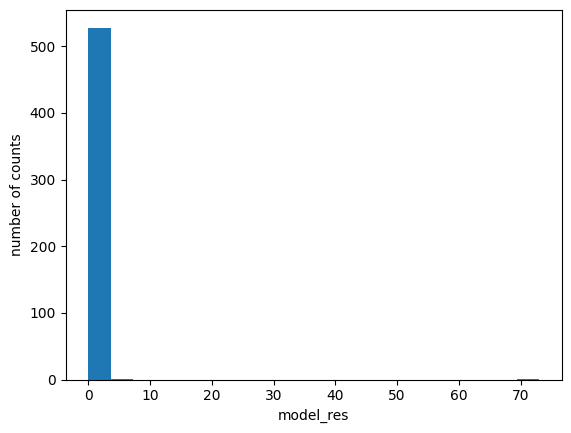

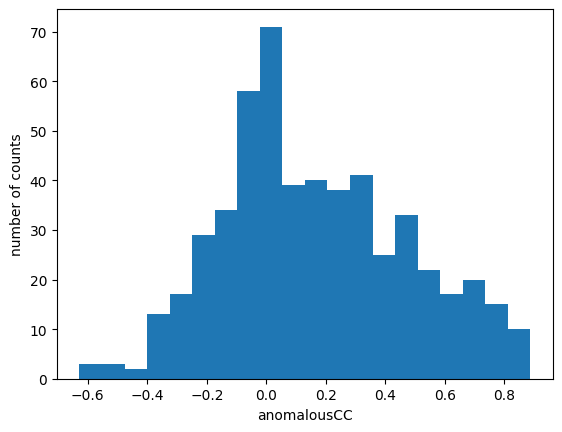

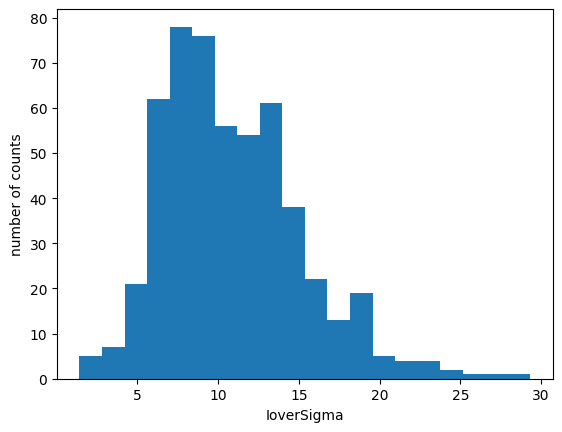

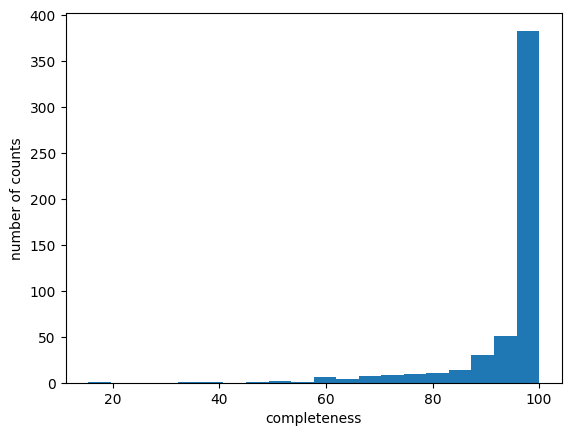

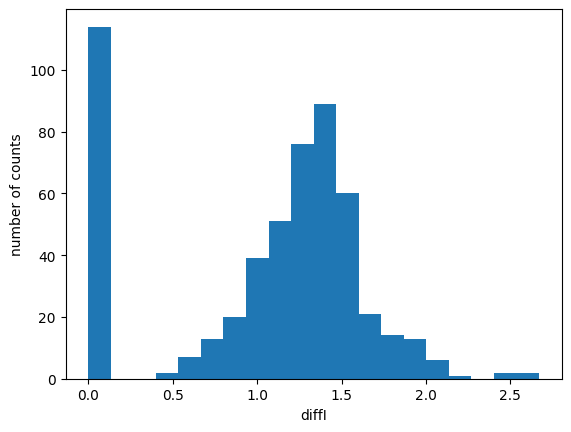

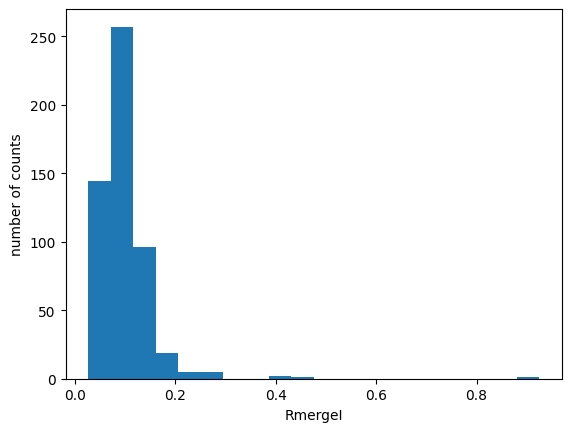

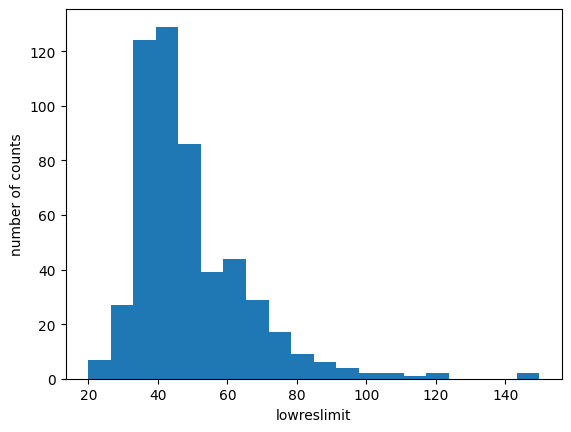

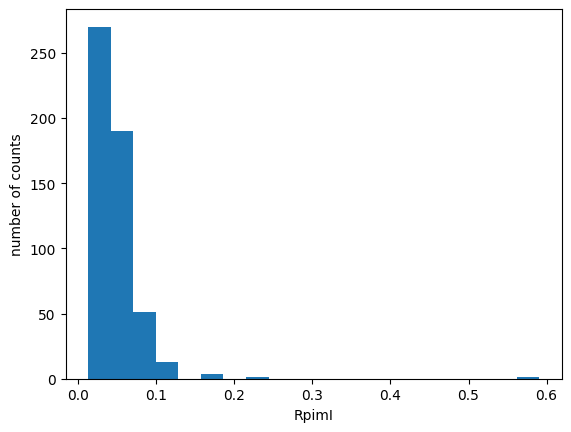

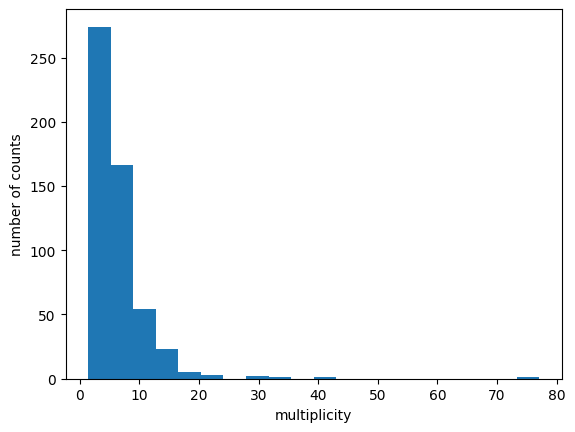

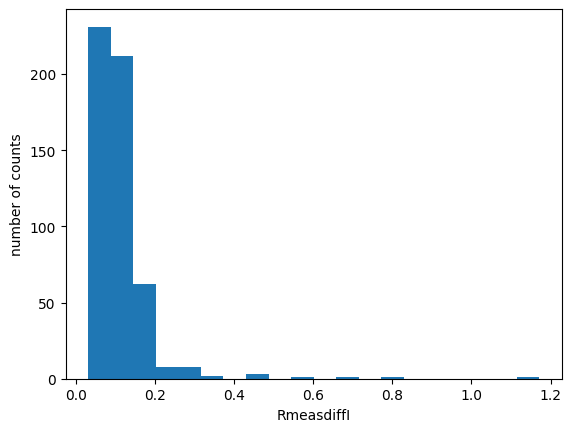

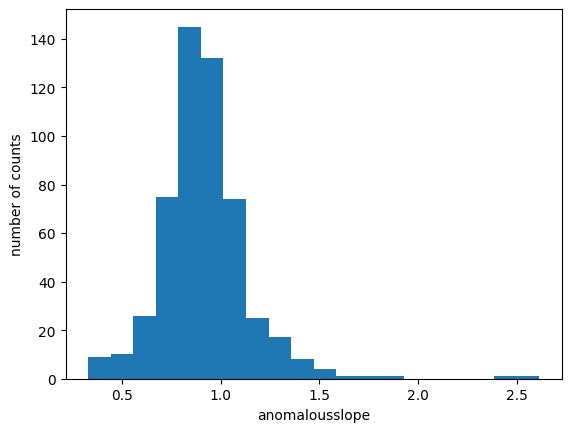

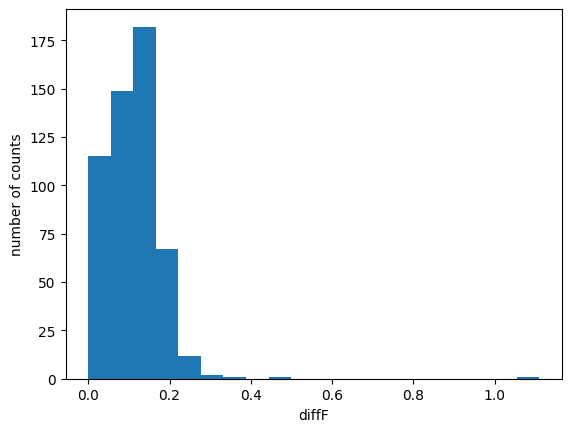

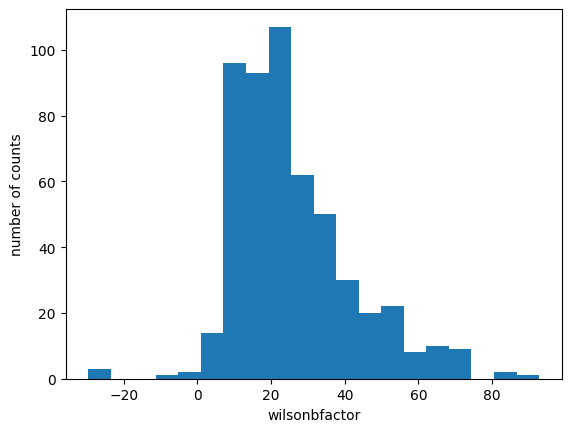

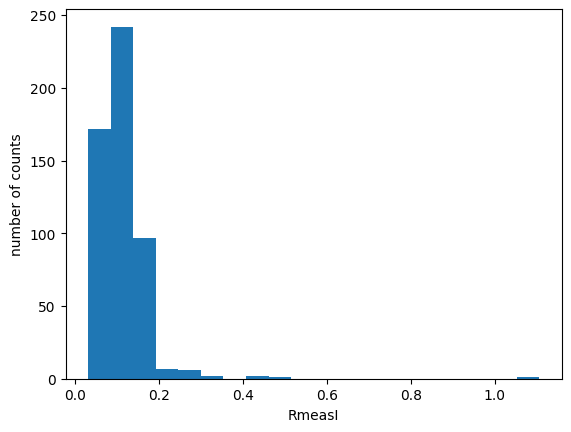

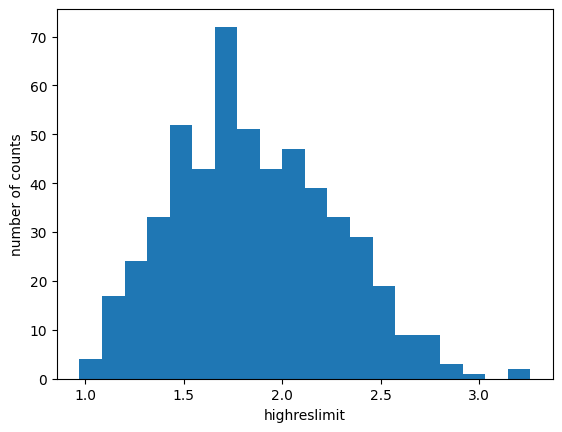

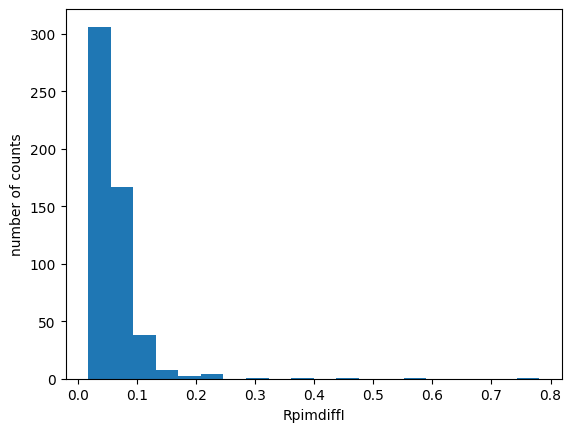

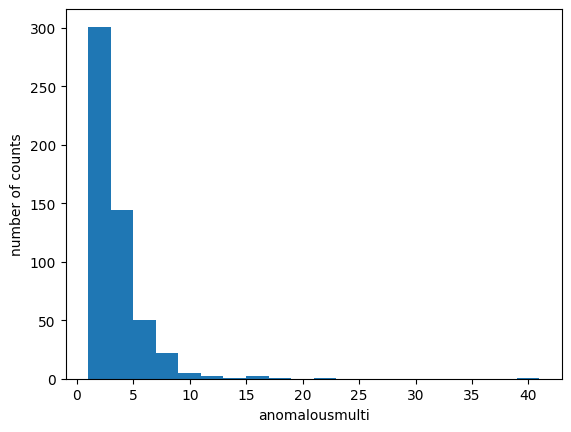

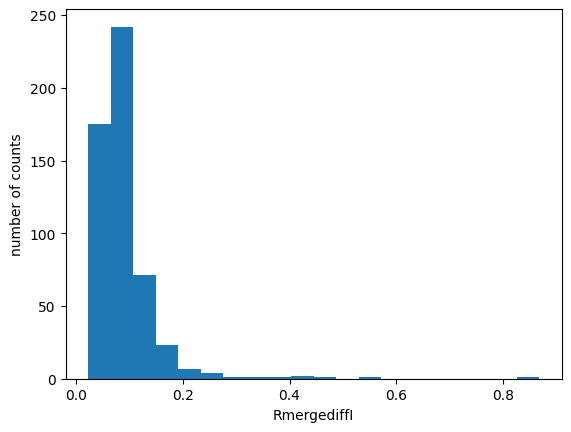

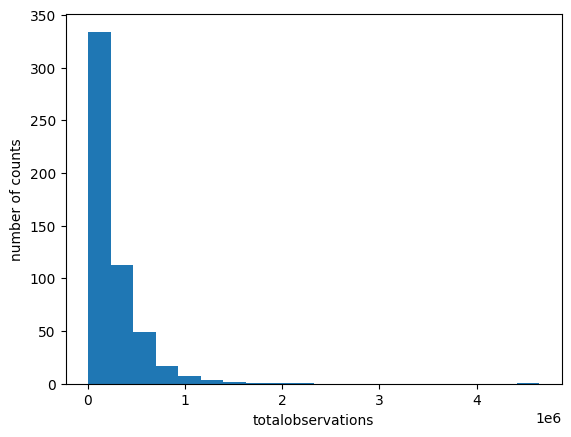

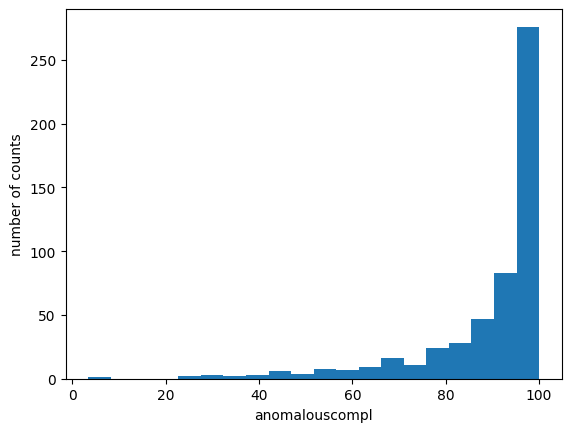

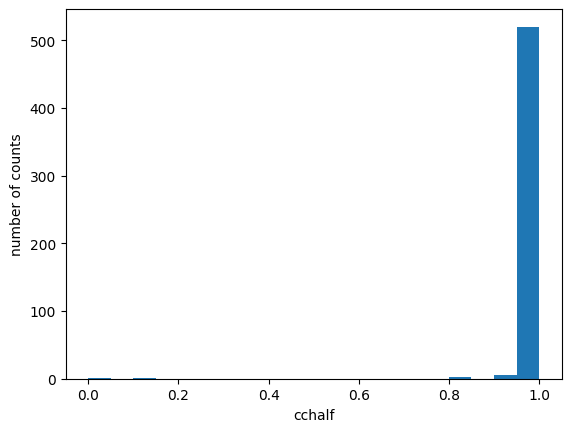

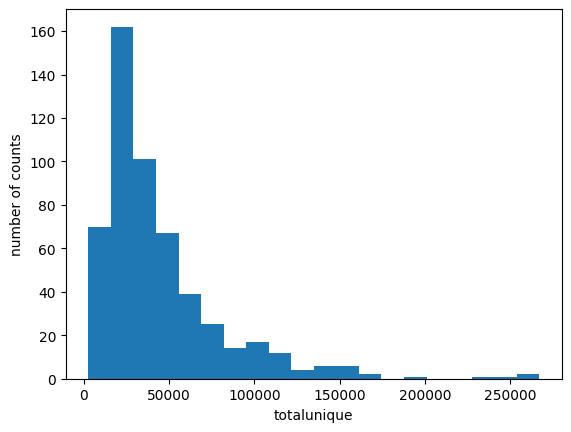

In [8]:
def plot_hist(data, itter):
  '''Plot a histogram for each feature.'''
  for name in itter:
    hist = plt.hist(data[name], bins=20)
    hist = plt.xlabel(name)
    hist = plt.ylabel('number of counts')
    plt.show()

plot_hist(X_train, data_columns_labels)

# Calculate Pearson's correlation coefficients for all features in pairs and plot corresponding correlation matrix coloured by positive and negative correlation strength

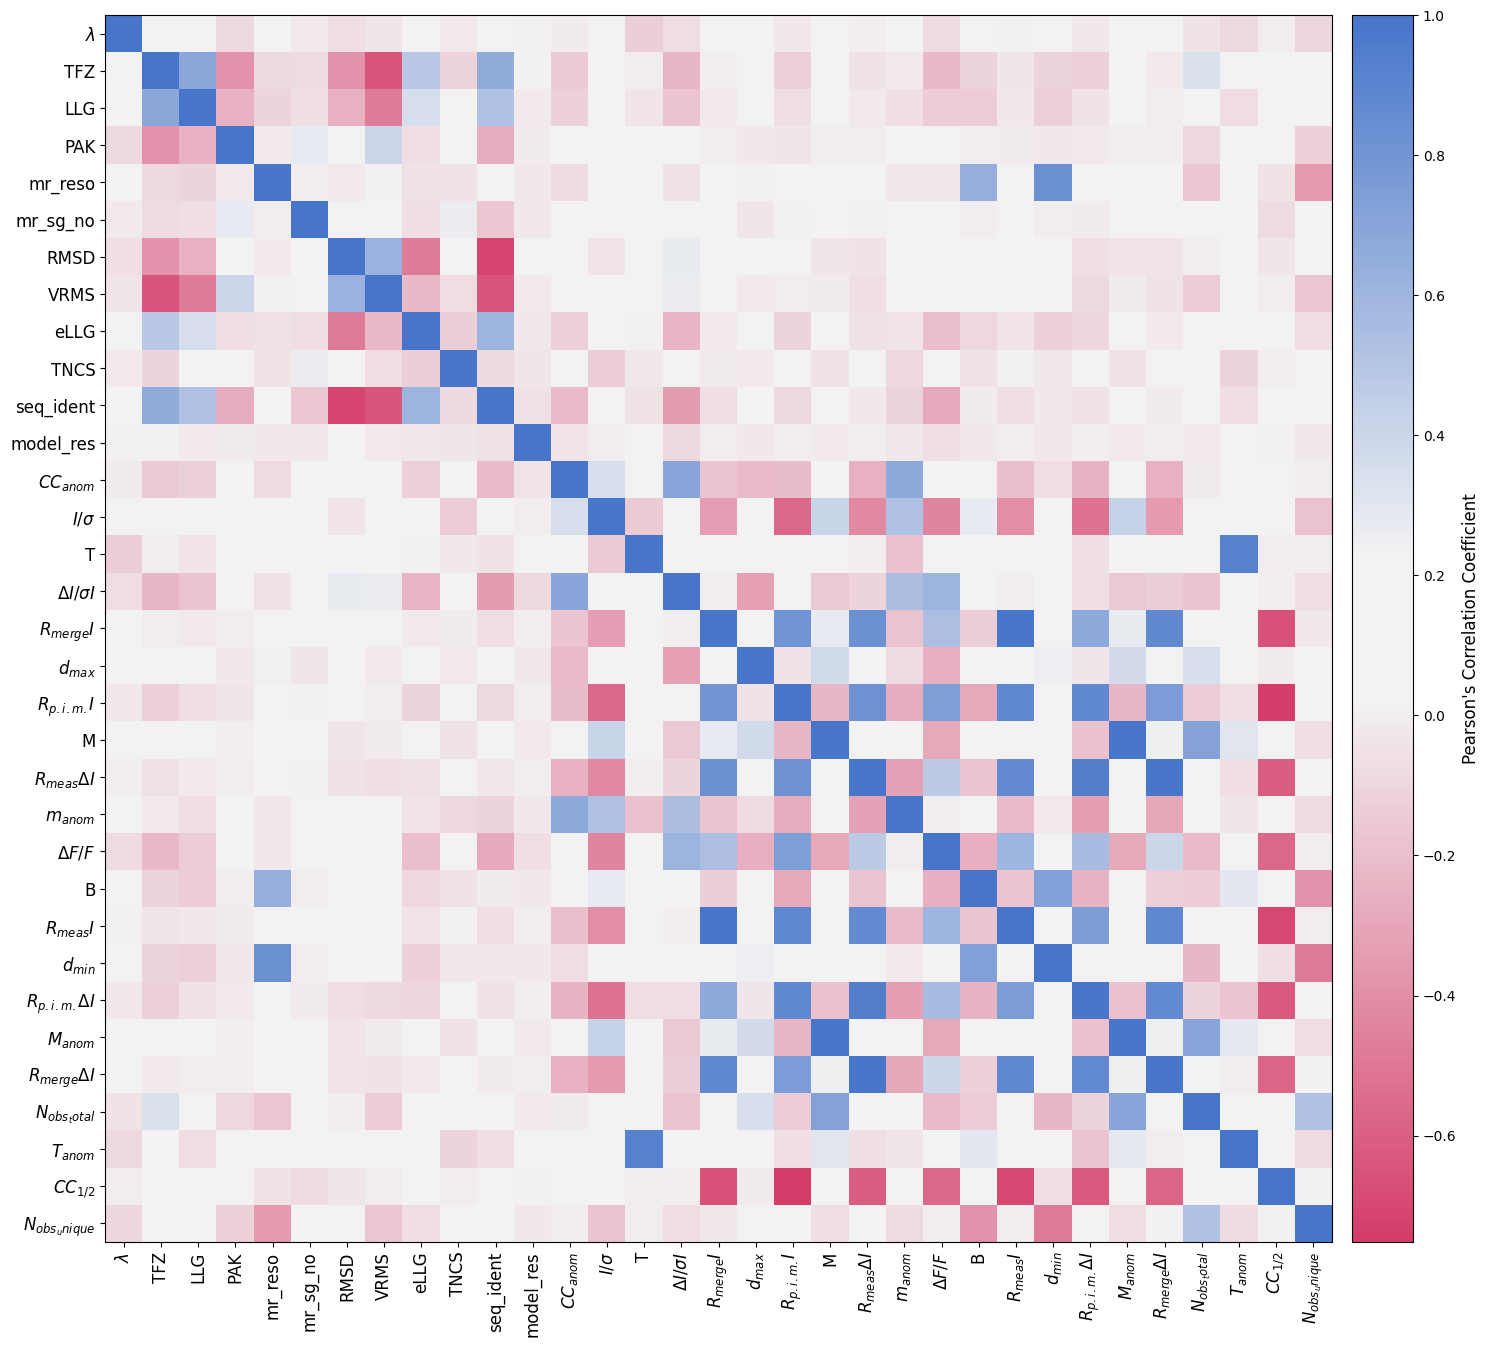

In [9]:
def feature_corr_mat(X_train):
  corr = X_train.corr()
      
  label_map = {
        'IoverSigma' : '$I/\\sigma$', 
        'cchalf' : "$CC_{1/2}$", 
        'RmergeI' : '$R_{merge}I$',
        'RmergediffI' : '$R_{merge}\\Delta I$', 
        'RmeasI' : '$R_{meas}I$',
        'RmeasdiffI' : '$R_{meas}\\Delta I$',
        'RpimI' : '$R_{p.i.m.}I$',
        'RpimdiffI' : '$R_{p.i.m.}\\Delta I$',
        'totalobservations' : '$N_{obs_total}$',
        'totalunique' : '$N_{obs_unique}$',
        'multiplicity' : 'M',
        'completeness' : 'T',
        'lowreslimit' : '$d_{max}$',
        'highreslimit' : '$d_{min}$',
        'wilsonbfactor' : 'B',
        'anomalousslope' : '$m_{anom}$',
        'anomalousCC' : '$CC_{anom}$',
        'anomalousmulti' : '$M_{anom}$',
        'anomalouscompl' : '$T_{anom}$',
        'diffI' : '$\\Delta I/\\sigma I$',
        'diffF' : '$\\Delta F/F$',
        'wavelength' : '$\\lambda$',
        'TFZ' : 'TFZ',
        'LLG' : 'LLG',
        'PAK' : 'PAK',
        'mr_reso' : 'mr_reso',
        'mr_sg_no' : 'mr_sg_no',
        'RMSD' : 'RMSD',
        'VRMS' : 'VRMS',
        'eLLG' : 'eLLG',
        'tncs' : 'TNCS',
        'seq_ident' : 'seq_ident',
        'model_res' : 'model_res'}

  yticklabels = [label_map[key] for key in corr.columns]
  xticklabels = [label_map[key] for key in corr.columns]
      
  fig = plt.figure(figsize=(15, 15))

  ax = plt.gca()
  im = ax.imshow(corr, cmap=sns.diverging_palette(0, 255, sep=32, n=256, center='light', as_cmap=True))  
  divider = make_axes_locatable(ax)
  cax = divider.append_axes('right', size='5%', pad=0.2)
  plt.colorbar(im, cax=cax).set_label("Pearson's Correlation Coefficient", fontsize=12)
  ax.set_xticks(np.arange(len(xticklabels)))
  ax.set_xticklabels(xticklabels, rotation=90, fontsize=12)
  ax.set_yticks(np.arange(len(yticklabels)))
  ax.set_yticklabels(yticklabels, fontsize=12)
  plt.tight_layout()
  plt.show()
    
feature_corr_mat(X_train)

# calculate scatter plot matrix where each scatter plot represents a pair of features

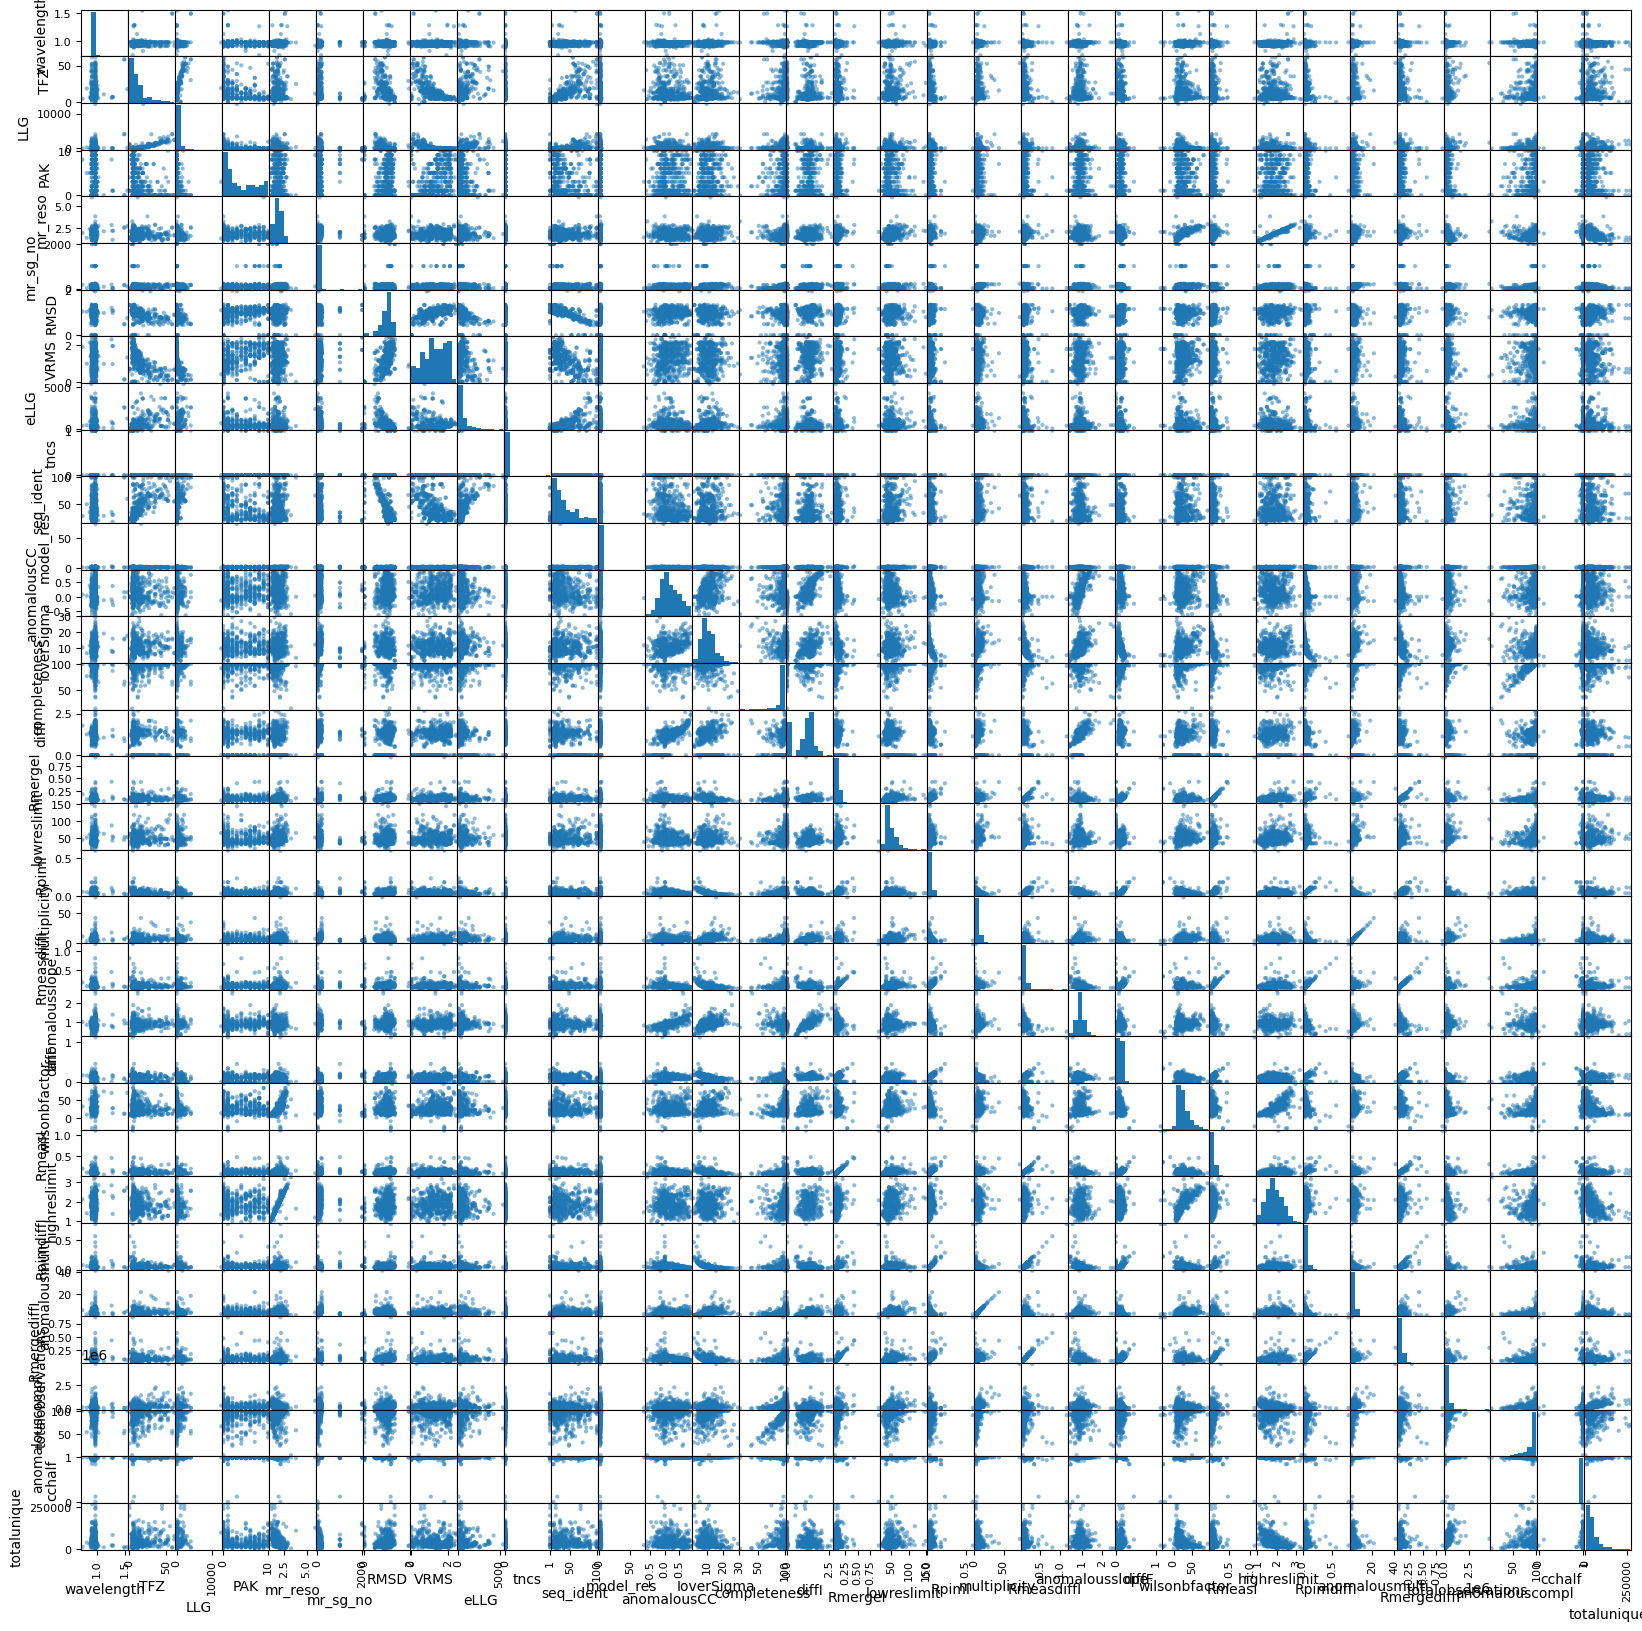

In [10]:
def plot_scatter_matrix(X_train):
  columns = [X_train.columns]
  for c in columns:
    if X_train.isnull().any().any() == True:
      X_train = X_train.dropna(axis=1)
  attr = list(X_train)    
  scatter_matrix(X_train[attr], figsize=(20,20))
  plt.show()  
  
plot_scatter_matrix(X_train)


# Plotting probability density function for each feature to evaluate continous data and its cumulative distribution function

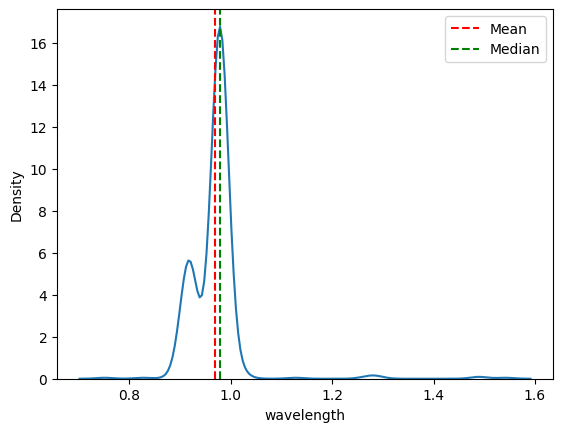

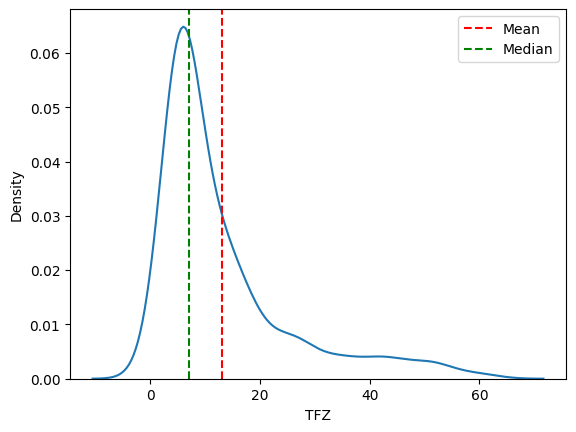

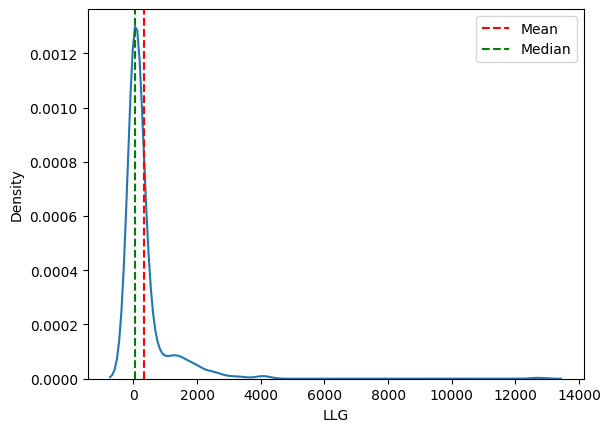

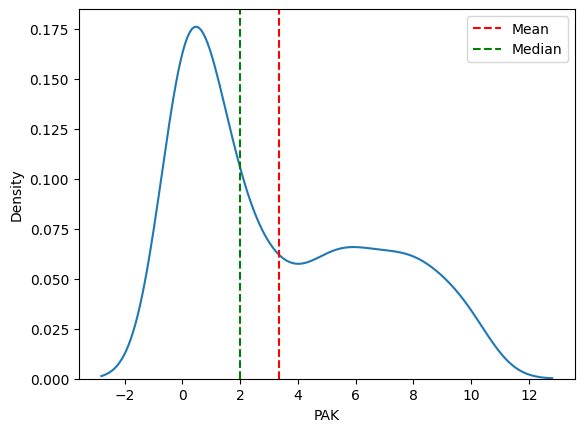

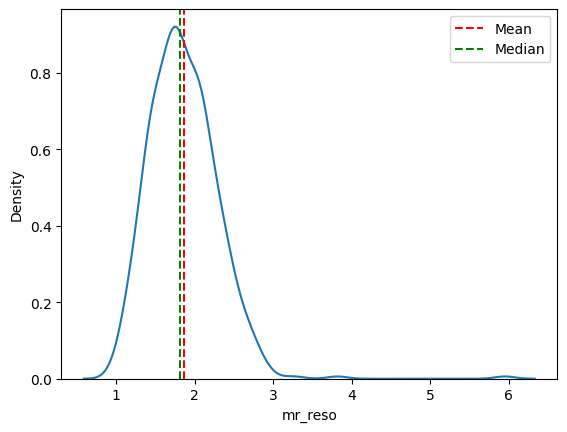

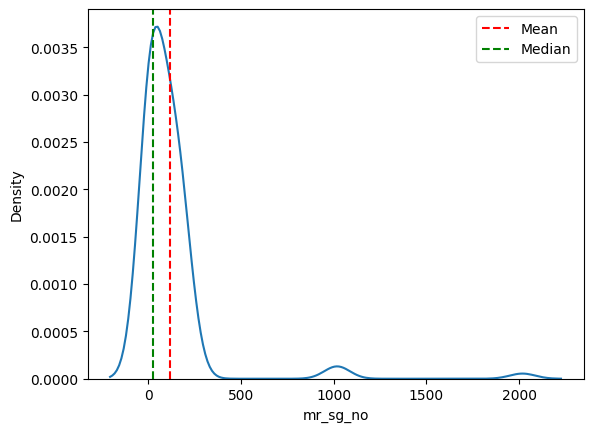

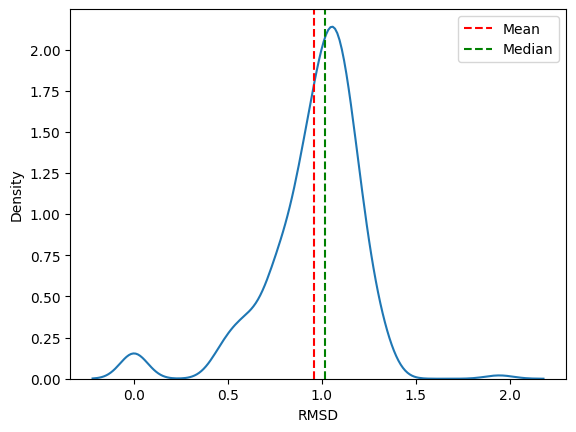

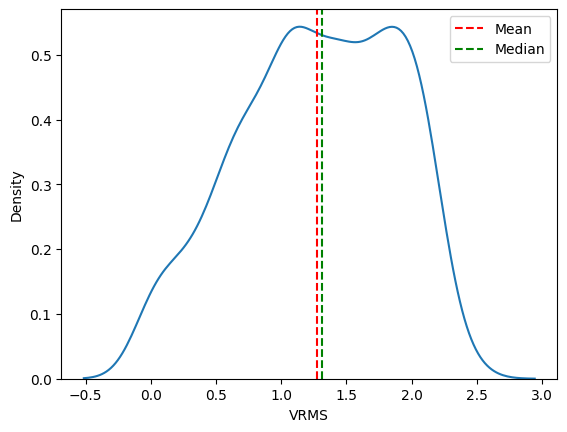

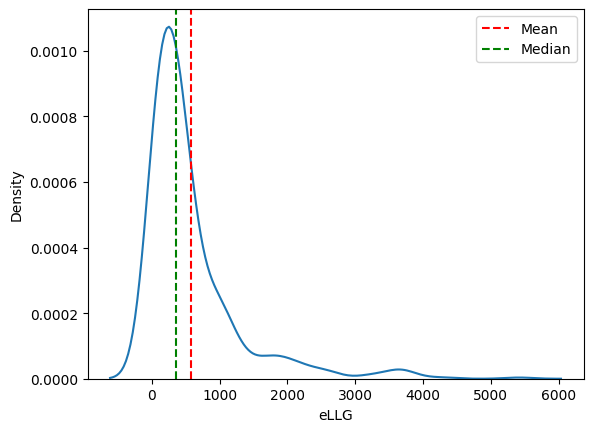

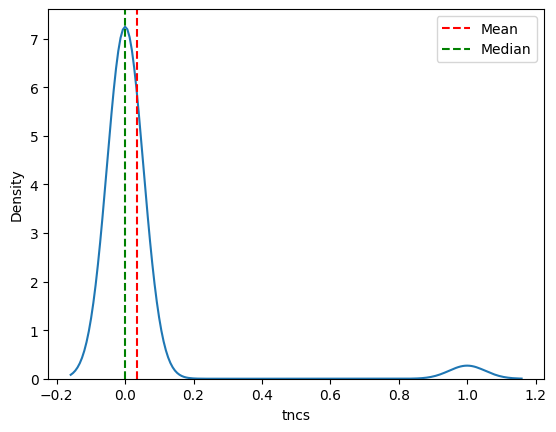

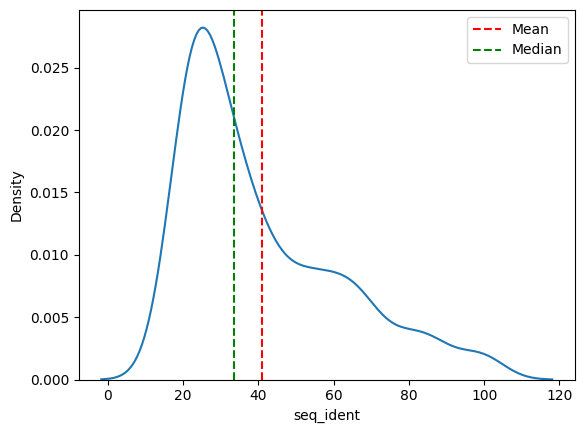

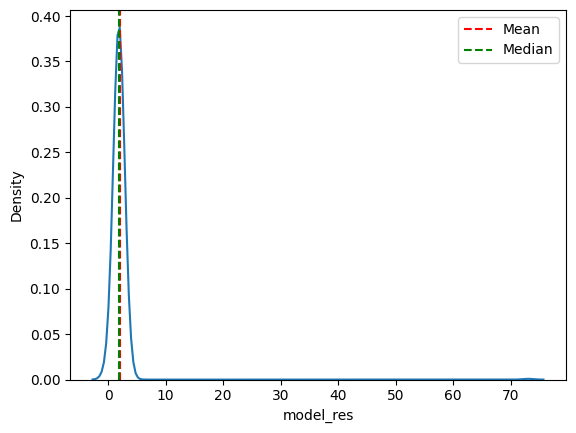

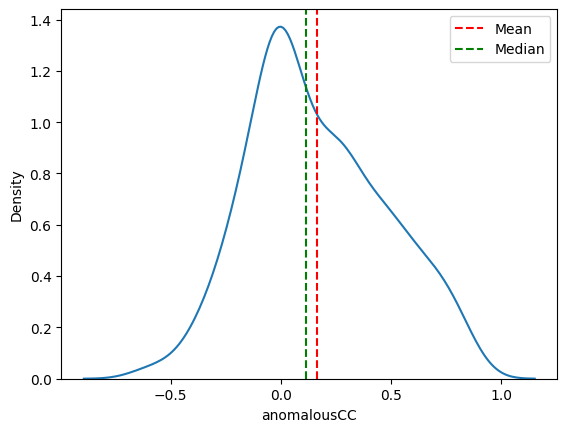

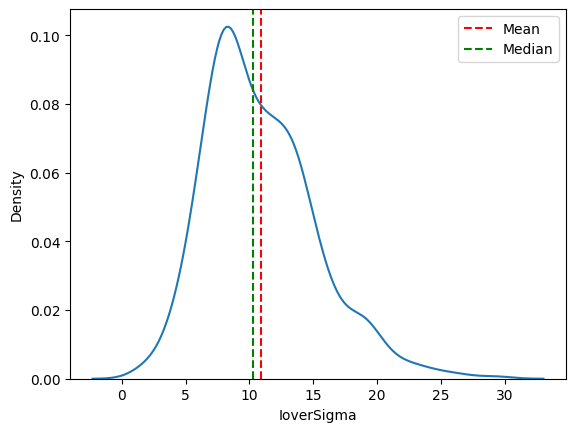

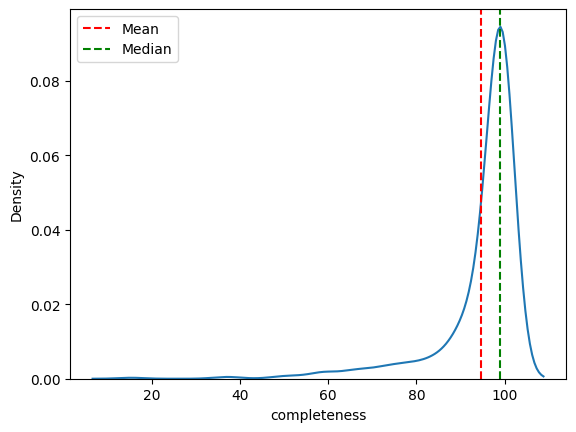

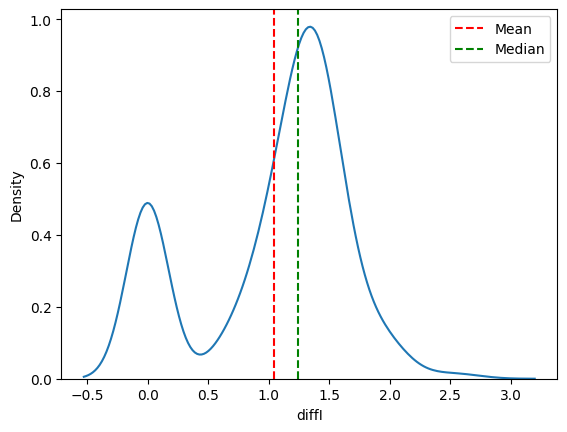

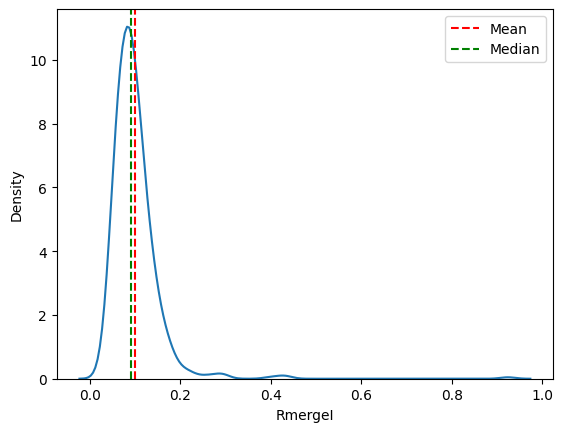

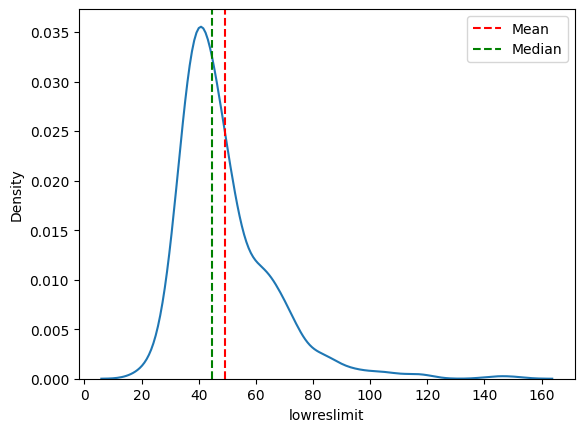

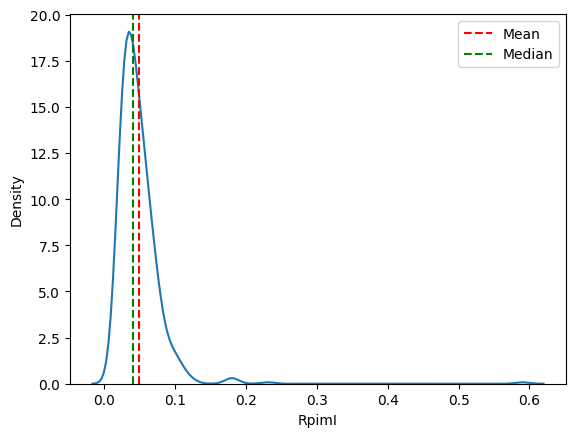

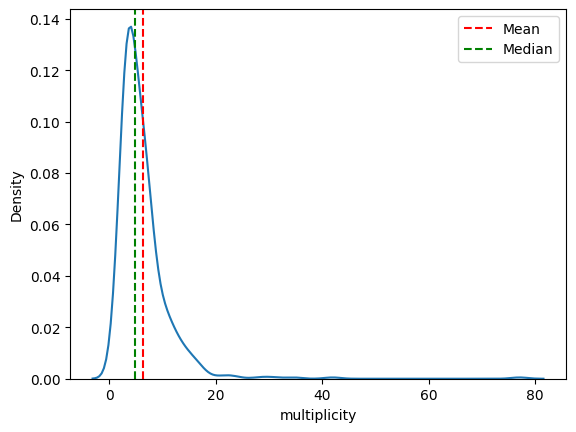

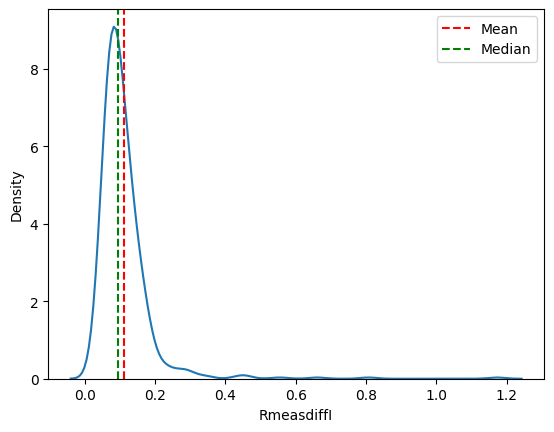

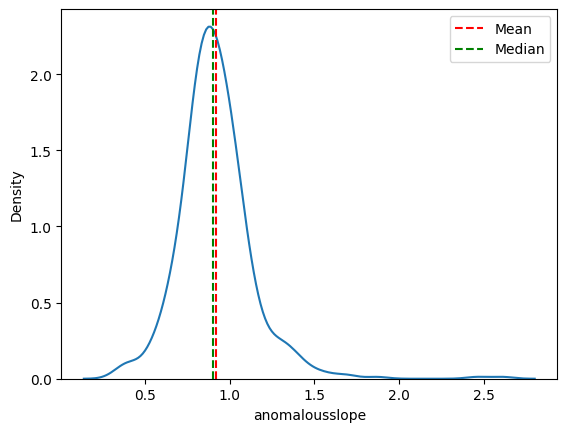

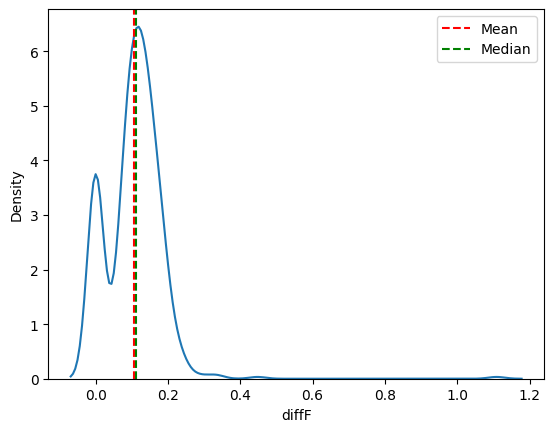

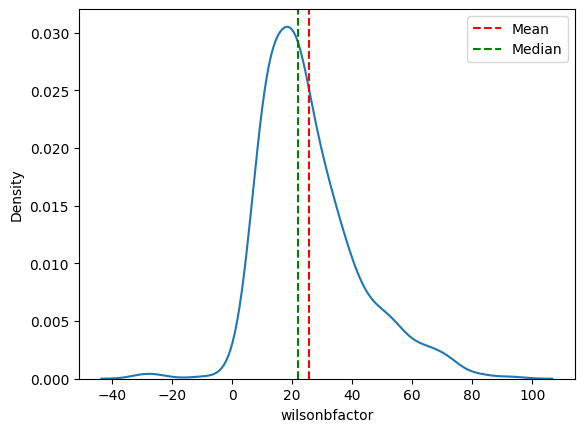

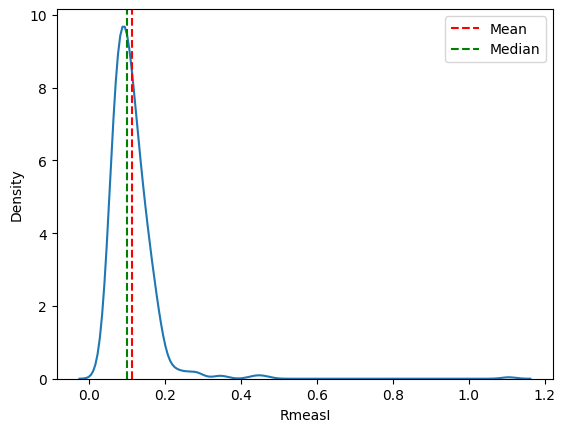

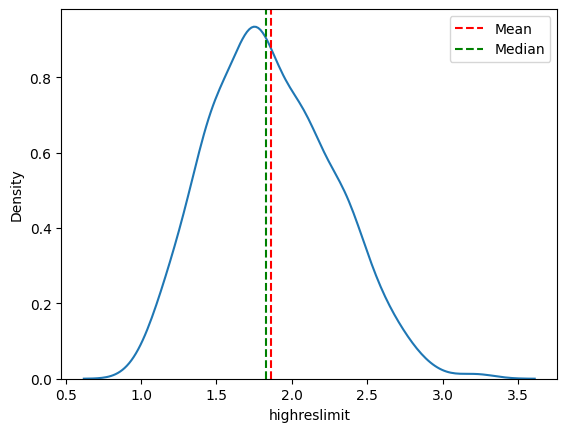

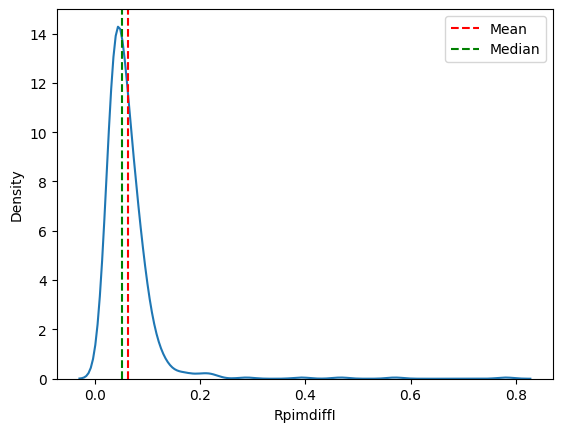

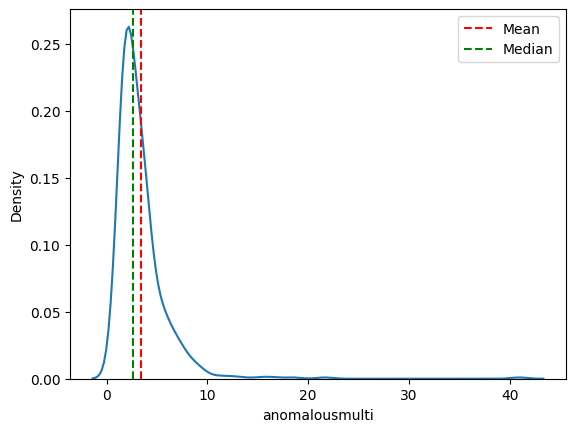

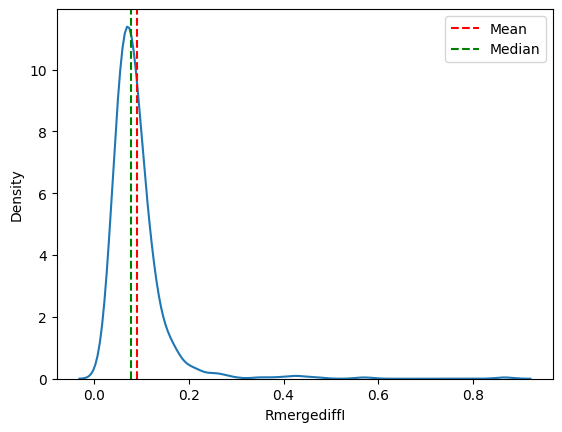

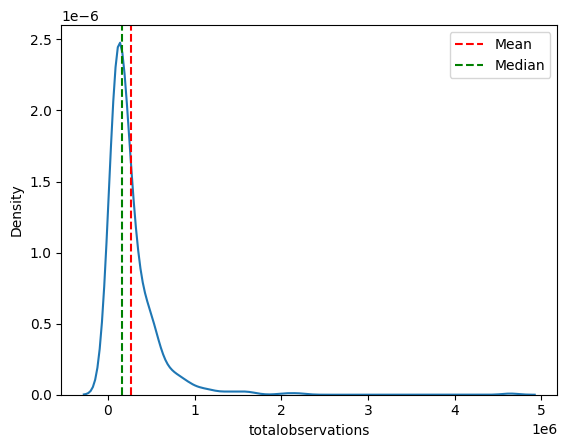

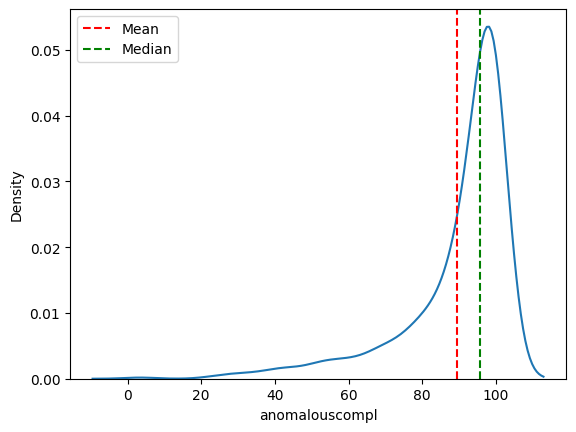

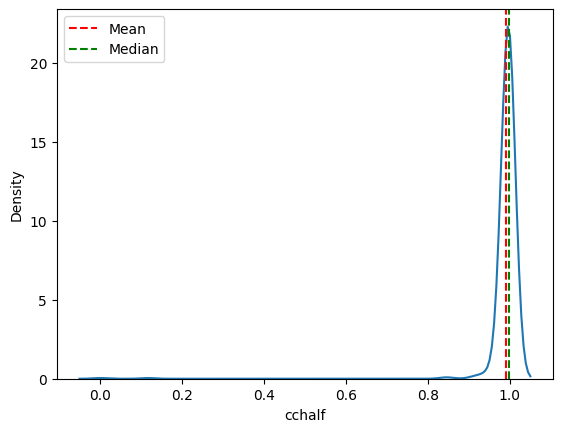

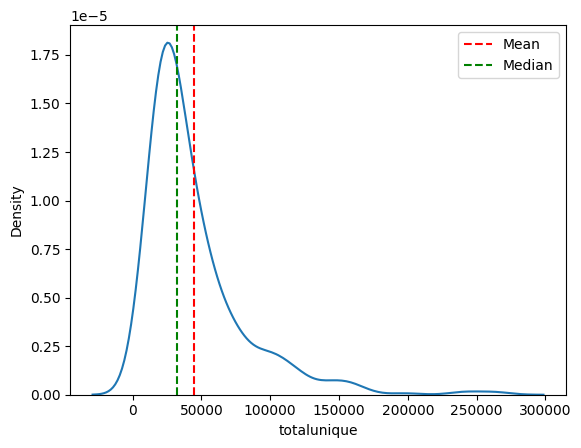

In [11]:
def plot_probability_density(X_train):
  itter = X_train.columns
  for name in itter:
    mean = np.mean(X_train[name])
    median = np.median(X_train[name])      
    sns.kdeplot(X_train[name])
    plt.axvline(mean, label='Mean', color='r', linestyle='--')  
    plt.axvline(median, label='Median', color='g', linestyle='--')        
    plt.legend(loc='best')
    plt.xlabel(name)
    plt.ylabel('Density')
    plt.show()

plot_probability_density(X_train)

# Plotting empirical cumulative distribution function for each feature

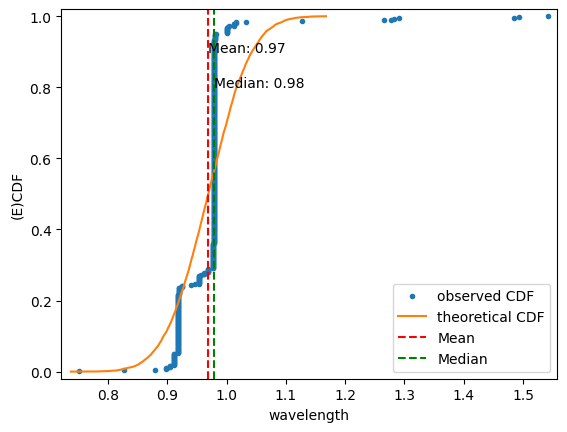

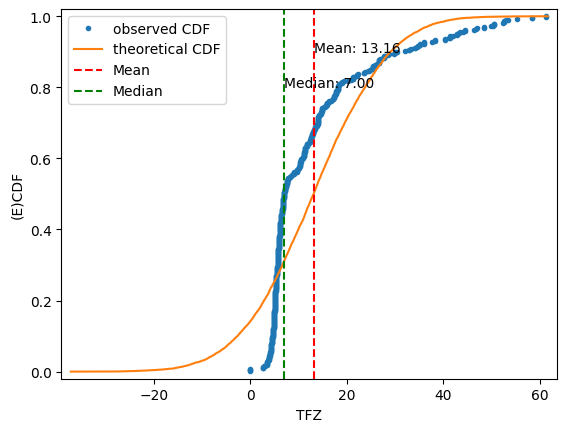

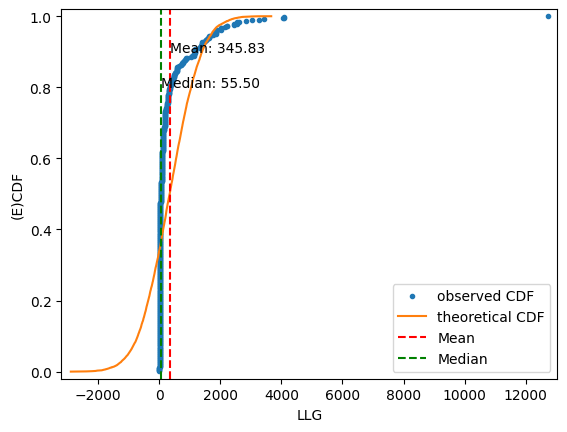

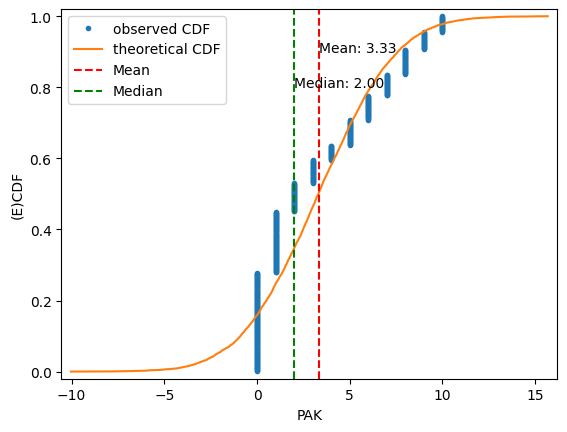

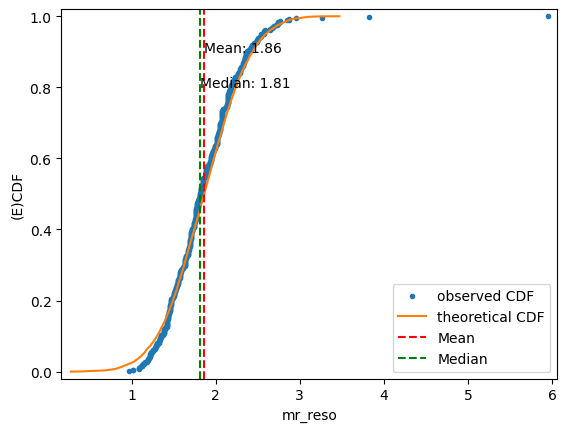

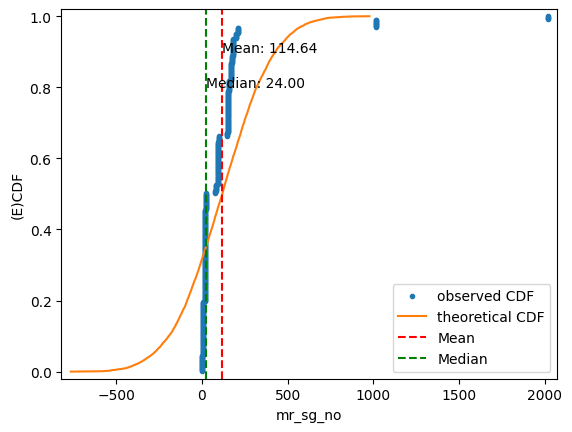

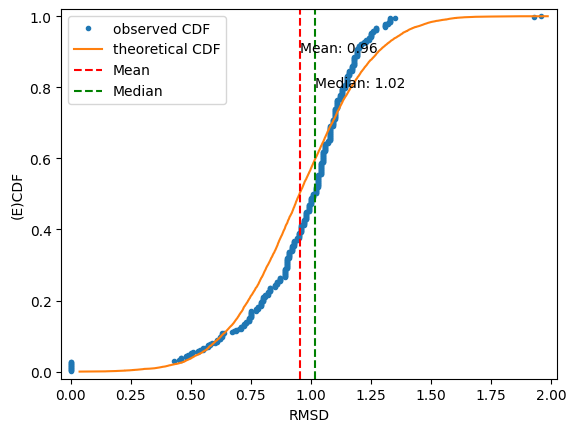

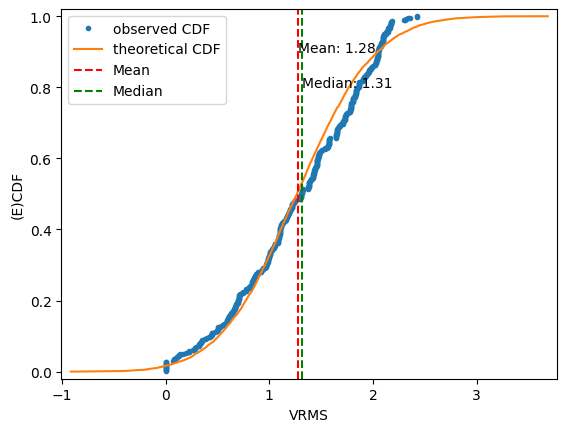

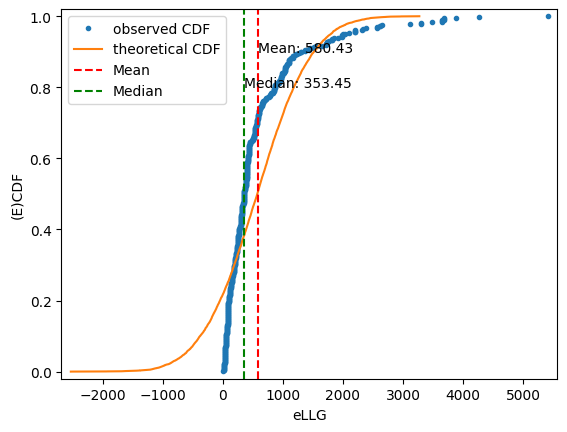

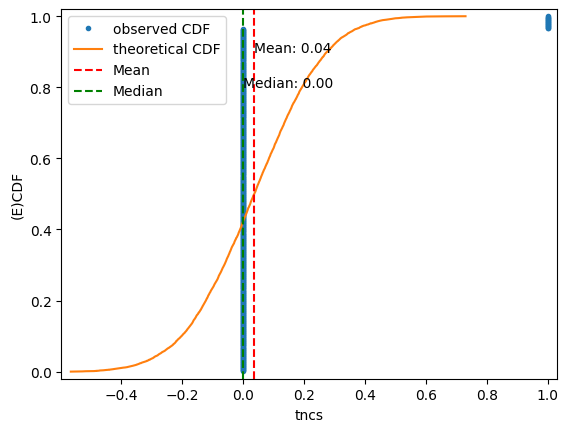

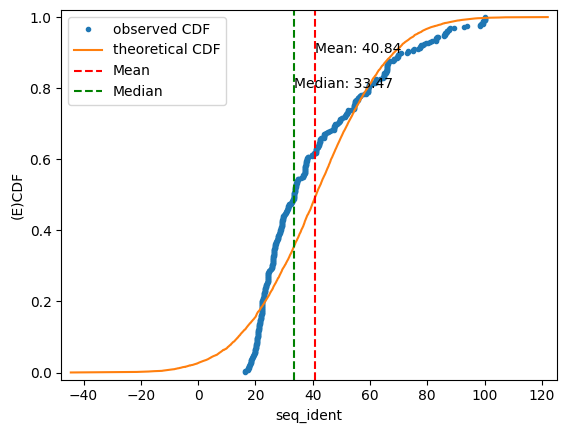

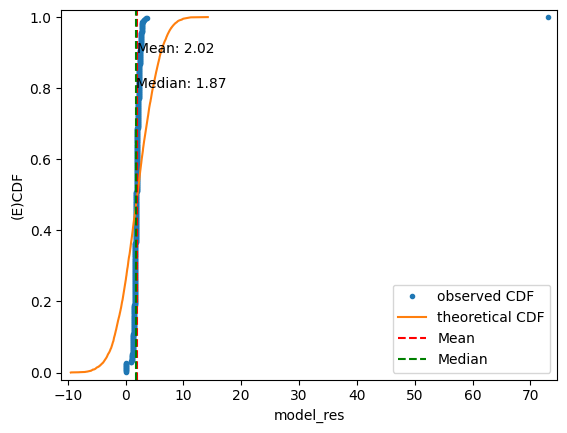

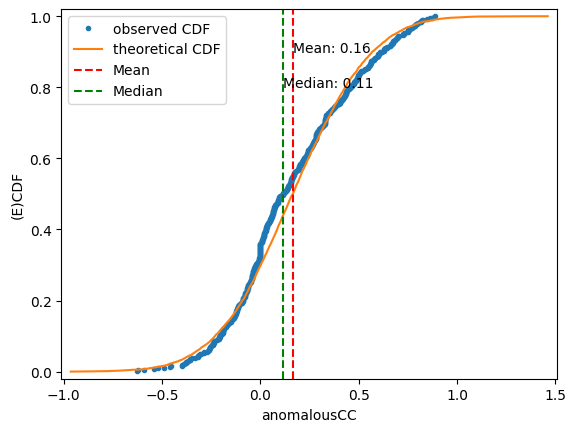

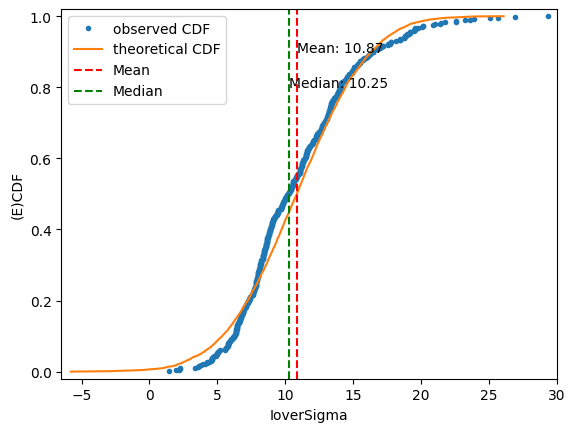

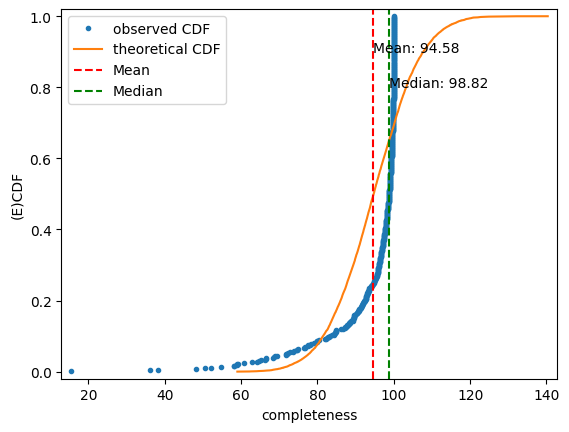

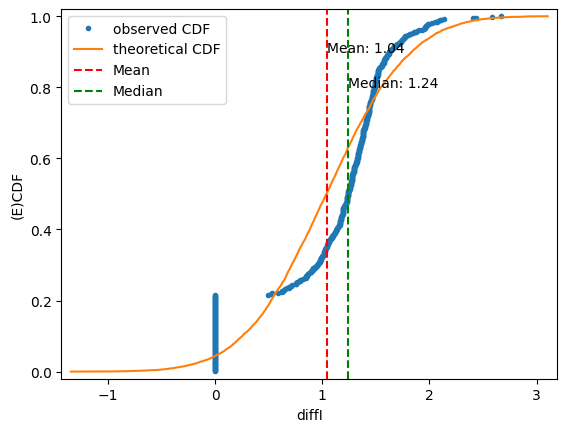

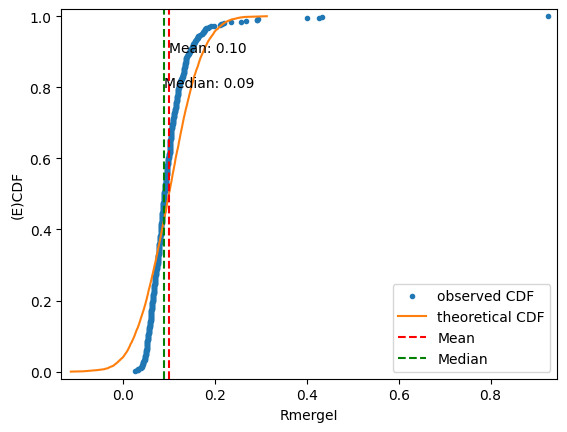

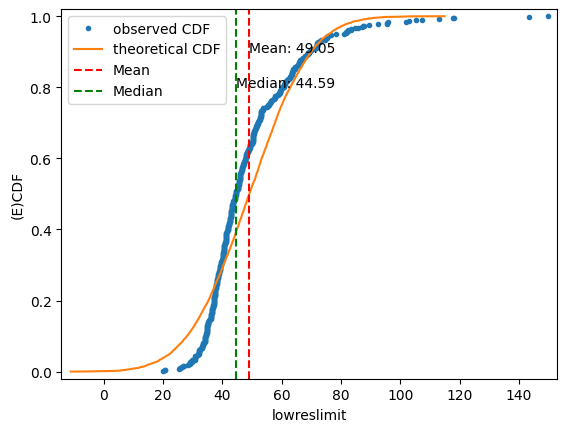

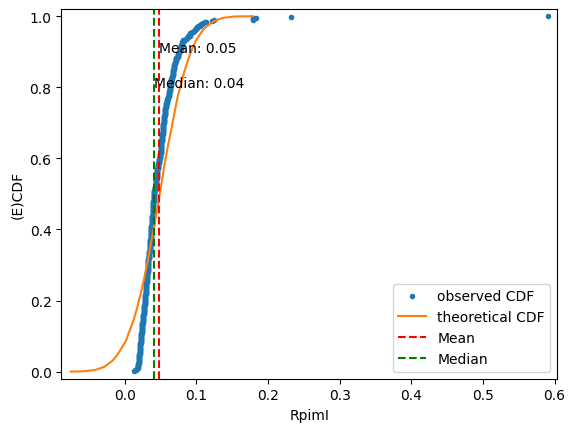

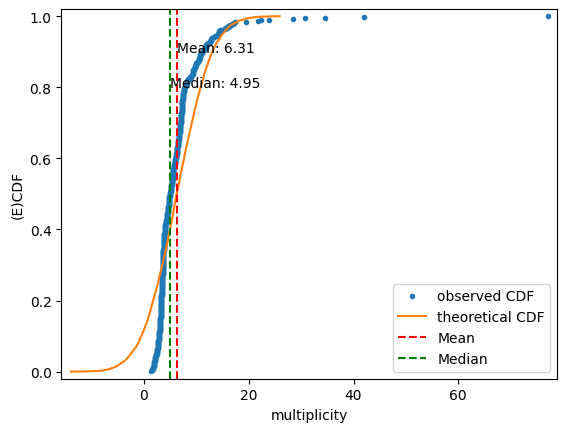

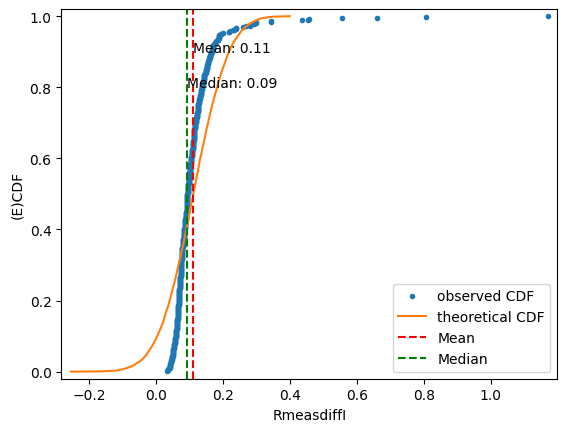

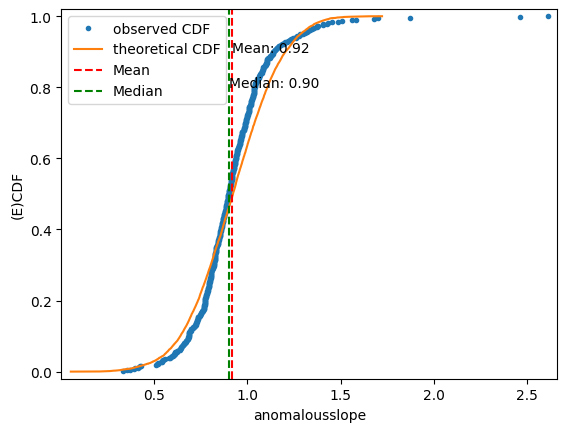

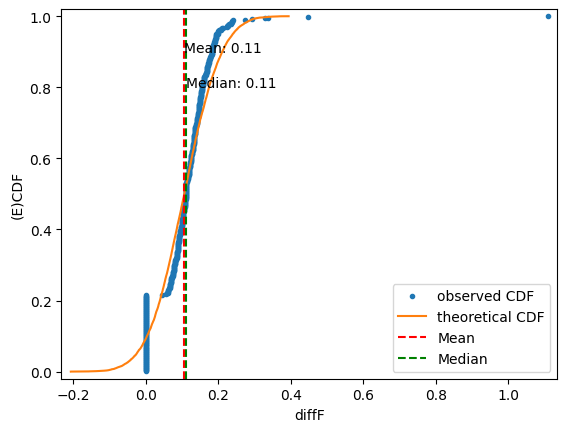

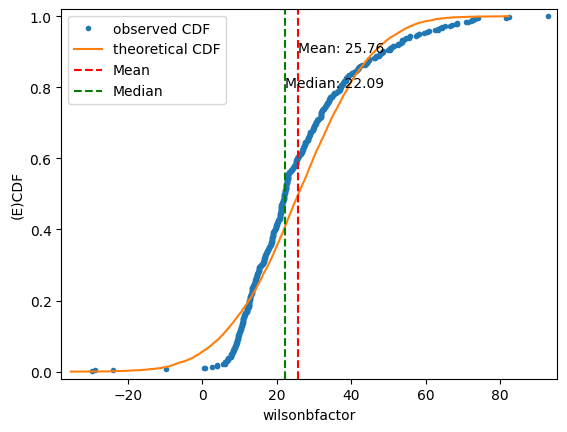

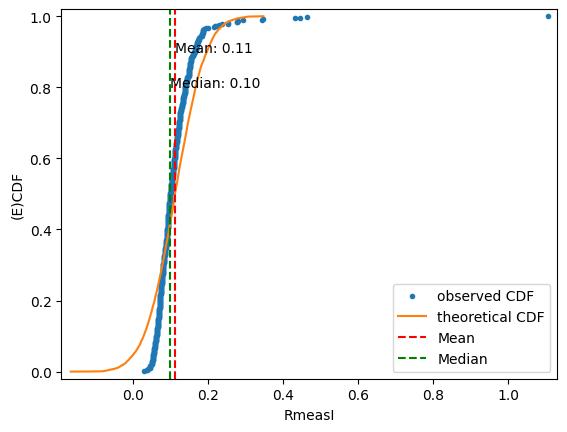

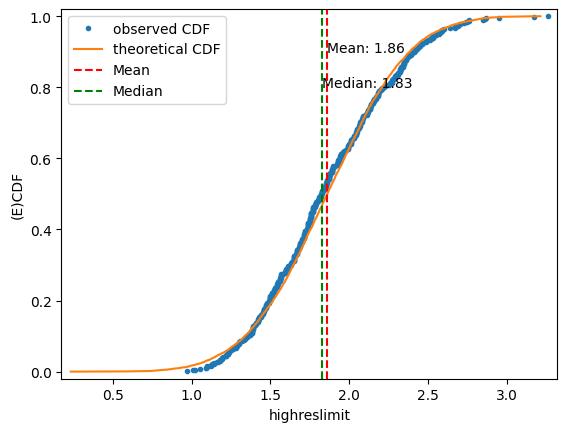

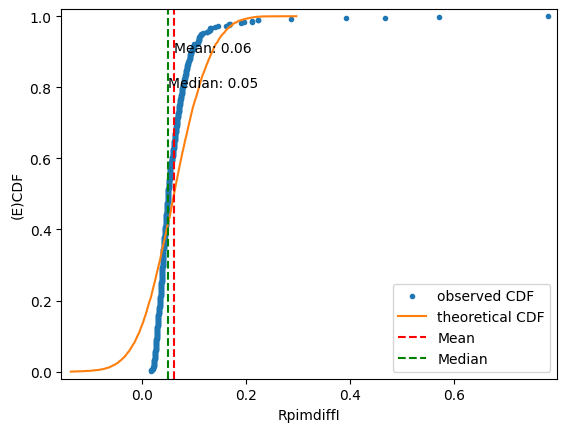

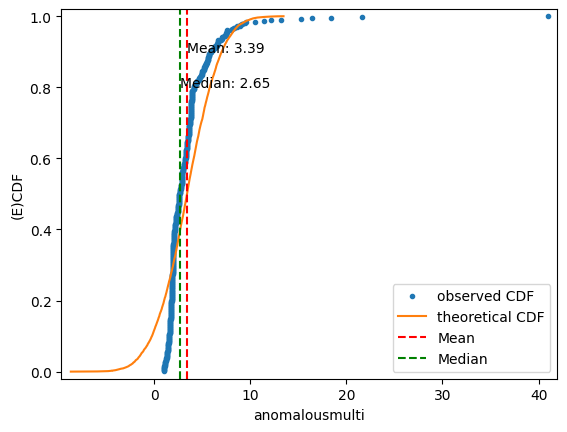

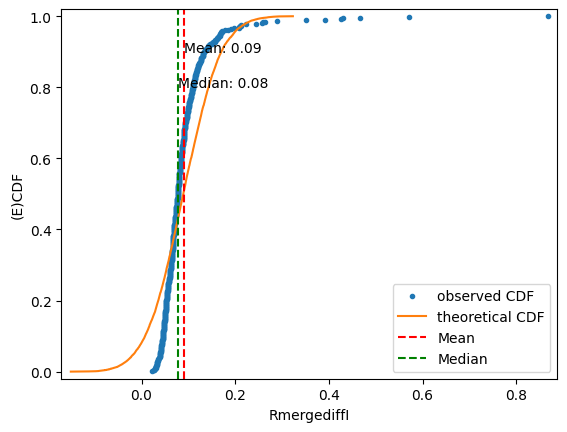

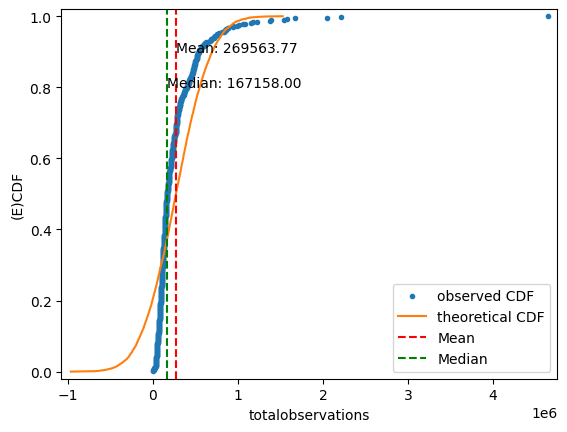

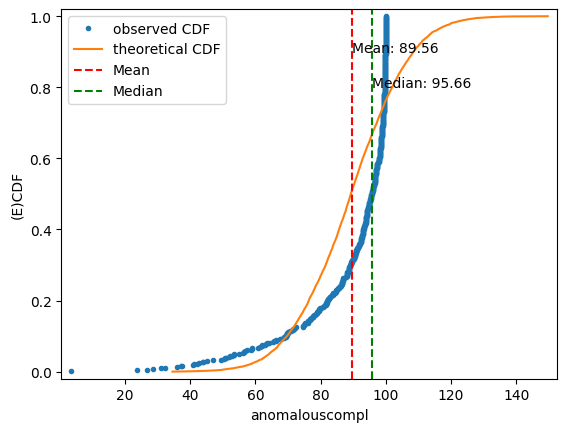

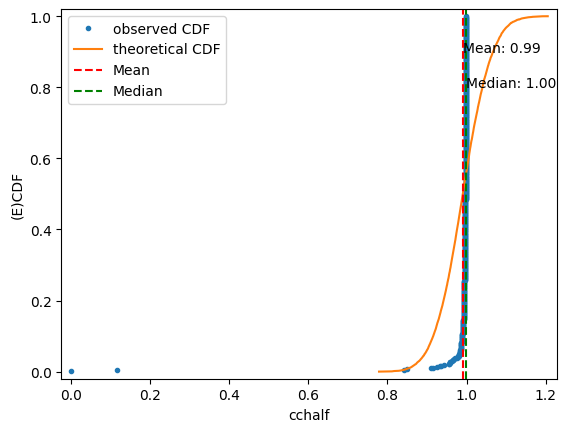

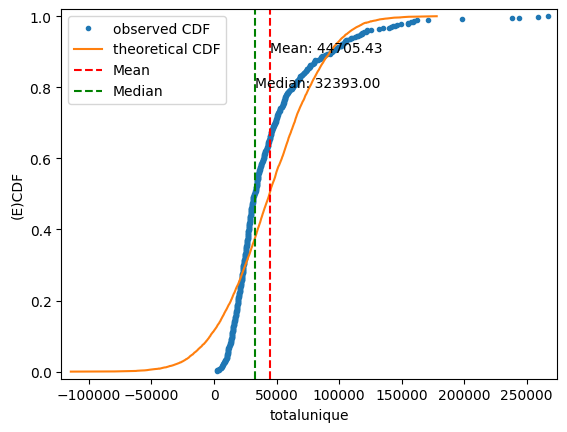

In [12]:
def plot_ecdf(X_train):
  itter = X_train.columns  
  for name in itter:
    #Number of data points:n
    n = len(X_train[name])
    #x-data for the ECDF:x
    x = np.sort(X_train[name])
    #y-data for the ECDF;y
    y = np.arange(1, n+1)/n
    mean = np.mean(X_train[name])
    median = np.median(X_train[name])
    std = np.std(X_train[name])
    percentile = np.percentile(X_train[name], [25, 50, 75])
    info = X_train[name].describe()
    samples = np.random.normal(mean, std, size=10000)
    n_theor = len(samples)
    x_theor = np.sort(samples)
    y_theor = np.arange(1, n_theor+1)/n_theor
    plt.plot(x, y, marker='.', linestyle='none', label='observed CDF')
    plt.plot(x_theor, y_theor, label='theoretical CDF')
    plt.axvline(mean, label='Mean', color='r', linestyle='--')
    plt.axvline(median, label='Median', color='g', linestyle='--')
    plt.text(mean, 0.9, 'Mean: %.2f' %mean)
    plt.text(median, 0.8, 'Median: %.2f' %median)
    plt.xlabel(name)
    plt.ylabel('(E)CDF')
    plt.margins(0.02)
    plt.legend(loc='best')
    plt.show()

plot_ecdf(X_train)

# Standardise data for PCA and recursive feature elimination with linear SVM

In [13]:
X_train_std = StandardScaler().fit_transform(X_train)

# Run PCA

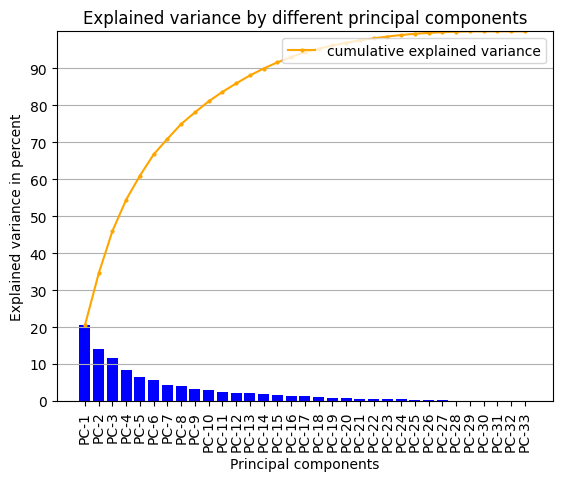

In [14]:
def pca_manual(X_train_std):
  mean_vec = np.mean(X_train_std, axis=0)
  cov_mat = (X_train_std - mean_vec).T.dot((X_train_std - mean_vec)) / (X_train_std.shape[0]-1)
  cov_mat = np.cov(X_train_std.T)

  eig_vals, eig_vecs = np.linalg.eig(cov_mat)
#  print('Eigenvectors \n%s' %eig_vecs)
#  print('\nEigenvalues \n%s' %eig_vals)
    
  for ev in eig_vecs:
    np.testing.assert_array_almost_equal(1.0, np.linalg.norm(ev), decimal=2)
    
  eig_pairs = [(np.abs(eig_vals[i]), eig_vecs[:,i]) for i in range(len(eig_vals))]

  # Sort the (eigenvalue, eigenvector) tuples from high to low
  eig_pairs.sort()
  eig_pairs.reverse()
#  print('Eigenvalues in descending order:')
#  for i in eig_pairs:
#    print(i[0])

  tot = sum(eig_vals)
  var_exp = [(i / tot)*100 for i in sorted(eig_vals, reverse=True)]
  cum_var_exp = np.cumsum(var_exp)
  
  PCs = ['PC-1','PC-2', 'PC-3', 'PC-4', 'PC-5', 'PC-6', 'PC-7', 'PC-8',
         'PC-9', 'PC-10', 'PC-11', 'PC-12', 'PC-13', 'PC-14', 'PC-15',
         'PC-16', 'PC-17', 'PC-18', 'PC-19', 'PC-20', 'PC-21', 'PC-22',
         'PC-23', 'PC-24', 'PC-25', 'PC-26', 'PC-27', 'PC-28', 'PC-29',
         'PC-30', 'PC-31', 'PC-32', 'PC-33']   
      
  plt.rcdefaults()
  fig, ax = plt.subplots()
  height = var_exp
  y_pos = range(len(PCs))
  height2 = cum_var_exp
  ax.bar(y_pos, height, align='center', color='blue')
  ax.plot(y_pos, height2, marker='o', markersize=2, color='orange', label='cumulative explained variance')
  plt.xticks(y_pos, PCs, rotation=90)
  plt.yticks(np.arange(0, 100, step=10))
  plt.title('Explained variance by different principal components')
  plt.ylabel('Explained variance in percent')
  plt.xlabel('Principal components')
  plt.legend(loc="upper right")
  ax.set_ylim((0, 100))
  plt.grid(True, axis='y', which='both')
  plt.show()

pca_manual(X_train_std)

# PCA to get 95% coverage

In [15]:
def run_pca_reduced(X_train_std):
  pca = PCA(n_components=0.95)#calculate the PCs to explain 95% of variance
  X_train_std_reduced = pca.fit_transform(X_train_std)
  coverage = pca.explained_variance_ratio_
  print(coverage)
  max_num_pc = len(pca.explained_variance_ratio_)
  print('Max number PCs needed for 95% coverage', max_num_pc)
  print(pca.singular_values_)
  return max_num_pc

run_pca_reduced(X_train_std)

[0.20495175 0.13999615 0.11493682 0.08492105 0.06489436 0.0574319
 0.04211143 0.04014412 0.03144404 0.02980586 0.02561004 0.02290262
 0.02164716 0.01871619 0.01672816 0.01413583 0.01331429 0.00952096]
Max number PCs needed for 95% coverage 18
[59.87158065 49.48264985 44.83575631 38.53918975 33.68979722 31.69359513
 27.13906743 26.49755845 23.45114643 22.83209447 21.16411207 20.01416367
 19.45787382 18.09271239 17.10483684 15.72372978 15.25997847 12.90432381]


18

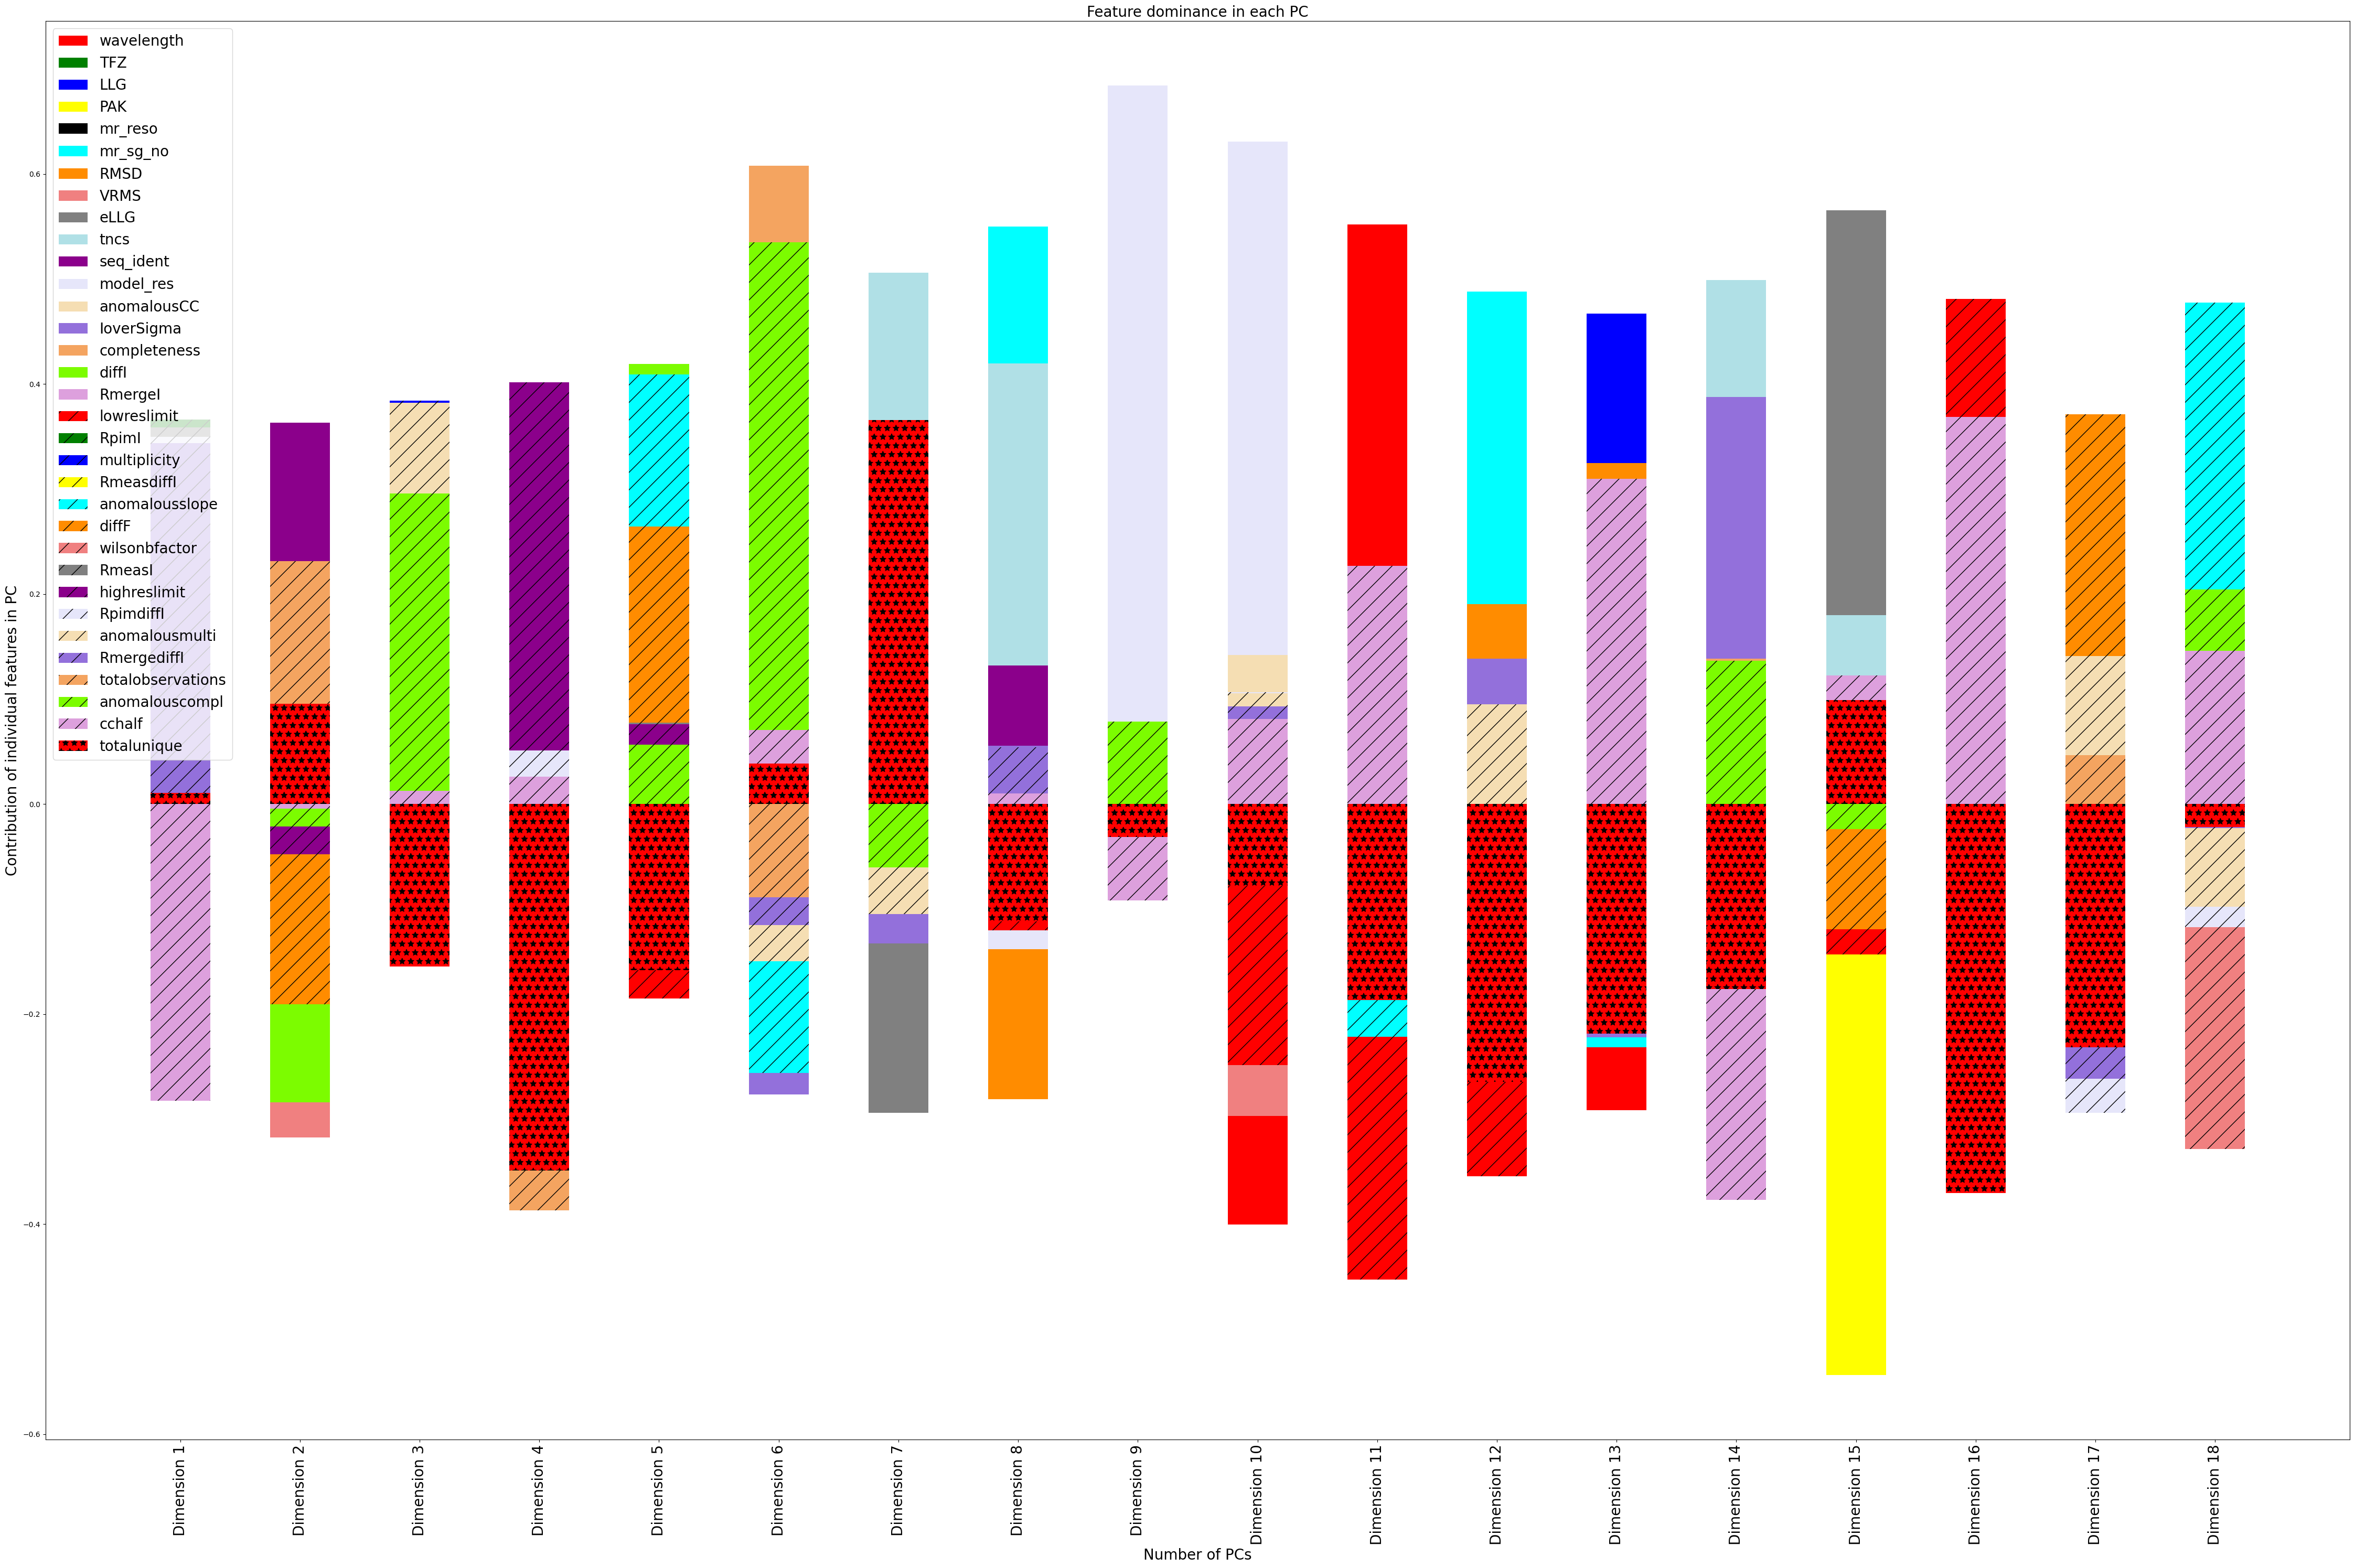

In [16]:
def feature_weights(X_train_std, columns, max_num_pc):
  pca = PCA(n_components = max_num_pc)
  pca.fit_transform(X_train_std)
  dimensions = ['Dimension {}'.format(i) for i in range(1,len(pca.components_)+1)]
             
  df = pd.DataFrame(pca.components_, columns=columns, index = dimensions)     
  df_i = df.T
  lab_i = df_i.columns
  N_i = len(lab_i)
  ind_i = np.arange(N_i)
  width = 0.5

  plt.figure(figsize=(45,30))

  p1_i = plt.bar(ind_i, df_i.iloc[0], width, color='red')
  p2_i = plt.bar(ind_i, df_i.iloc[1], width, color='green')
  p3_i = plt.bar(ind_i, df_i.iloc[2], width, color='blue')
  p4_i = plt.bar(ind_i, df_i.iloc[3], width, color='yellow')
  p5_i = plt.bar(ind_i, df_i.iloc[4], width, color='black')
  p6_i = plt.bar(ind_i, df_i.iloc[5], width, color='cyan')
  p7_i = plt.bar(ind_i, df_i.iloc[6], width, color='darkorange')
  p8_i = plt.bar(ind_i, df_i.iloc[7], width, color='lightcoral')
  p9_i = plt.bar(ind_i, df_i.iloc[8], width, color='gray')
  p10_i = plt.bar(ind_i, df_i.iloc[9], width, color='powderblue')
  p11_i = plt.bar(ind_i, df_i.iloc[10], width, color='darkmagenta')
  p12_i = plt.bar(ind_i, df_i.iloc[11], width, color='lavender')
  p13_i = plt.bar(ind_i, df_i.iloc[12], width, color='wheat')
  p14_i = plt.bar(ind_i, df_i.iloc[13], width, color='mediumpurple')
  p15_i = plt.bar(ind_i, df_i.iloc[14], width, color='sandybrown')
  p16_i = plt.bar(ind_i, df_i.iloc[15], width, color='lawngreen')
  p17_i = plt.bar(ind_i, df_i.iloc[16], width, color='plum')
  p18_i = plt.bar(ind_i, df_i.iloc[17], width, color='red', hatch="/")
  p19_i = plt.bar(ind_i, df_i.iloc[18], width, color='green', hatch="/")
  p20_i = plt.bar(ind_i, df_i.iloc[19], width, color='blue', hatch="/")
  p21_i = plt.bar(ind_i, df_i.iloc[20], width, color='yellow', hatch="/")
  p22_i = plt.bar(ind_i, df_i.iloc[21], width, color='cyan', hatch="/")
  p23_i = plt.bar(ind_i, df_i.iloc[22], width, color='darkorange', hatch="/")
  p24_i = plt.bar(ind_i, df_i.iloc[23], width, color='lightcoral', hatch="/")
  p25_i = plt.bar(ind_i, df_i.iloc[24], width, color='gray', hatch="/")
  p26_i = plt.bar(ind_i, df_i.iloc[25], width, color='darkmagenta', hatch="/")
  p27_i = plt.bar(ind_i, df_i.iloc[26], width, color='lavender', hatch="/")
  p28_i = plt.bar(ind_i, df_i.iloc[27], width, color='wheat', hatch="/")
  p29_i = plt.bar(ind_i, df_i.iloc[28], width, color='mediumpurple', hatch="/")
  p30_i = plt.bar(ind_i, df_i.iloc[29], width, color='sandybrown', hatch="/")
  p31_i = plt.bar(ind_i, df_i.iloc[30], width, color='lawngreen', hatch="/")
  p32_i = plt.bar(ind_i, df_i.iloc[31], width, color='plum', hatch="/")
  p33_i = plt.bar(ind_i, df_i.iloc[32], width, color='red', hatch="*")
           
  plt.title('Feature dominance in each PC', fontsize=20)
  plt.xlabel('Number of PCs', fontsize=20)
  plt.ylabel('Contribution of individual features in PC', fontsize=20)
  plt.xticks(ind_i, lab_i, rotation=90, fontsize=20)
  plt.legend(labels=df_i.index, loc='best', fontsize=20)
  plt.tight_layout()
  plt.show()

feature_weights(X_train_std, X_train.columns, 18)     

# Recursive feature elimination to identify most important features

[False  True  True False False False  True  True  True False  True False
 False False False False False False False False False False False False
 False False False False False False False False False]
Feature ranking : [24  1  1  2 20 27  1  1  1  6  1  5 11 21  3 15  9 16  8 25 28 12 19  7
 22 23 14 26 13 17  4 10 18] 

Features sorted by their rank: 

[(np.int64(1), 'LLG'), (np.int64(1), 'RMSD'), (np.int64(1), 'TFZ'), (np.int64(1), 'VRMS'), (np.int64(1), 'eLLG'), (np.int64(1), 'seq_ident'), (np.int64(2), 'PAK'), (np.int64(3), 'completeness'), (np.int64(4), 'anomalouscompl'), (np.int64(5), 'model_res'), (np.int64(6), 'tncs'), (np.int64(7), 'wilsonbfactor'), (np.int64(8), 'RpimI'), (np.int64(9), 'RmergeI'), (np.int64(10), 'cchalf'), (np.int64(11), 'anomalousCC'), (np.int64(12), 'anomalousslope'), (np.int64(13), 'RmergediffI'), (np.int64(14), 'RpimdiffI'), (np.int64(15), 'diffI'), (np.int64(16), 'lowreslimit'), (np.int64(17), 'totalobservations'), (np.int64(18), 'totalunique'), (np.int

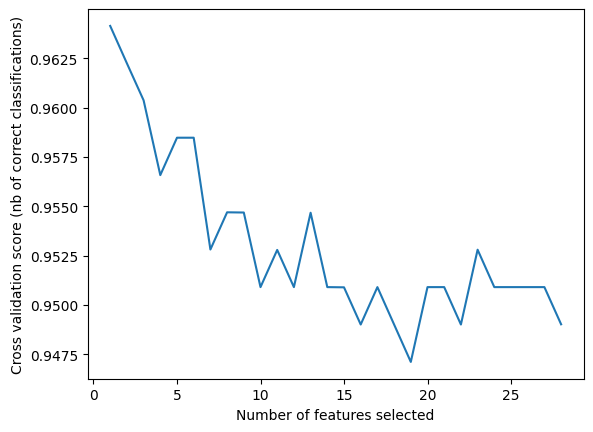

In [28]:
def run_rfecv_and_plot(X_train_std, columns, y_train):
  svc = SVC(kernel="linear", C=0.1, class_weight='balanced')
  # The "accuracy" scoring is proportional to the number of correct
  # classifications
  rfecv = RFECV(estimator = svc, step=1, min_features_to_select=6, cv=StratifiedKFold(3), scoring='accuracy')
  rfecv.fit(X_train_std, y_train)
      
  feature_names = columns
      
  feature_selection = rfecv.support_
  print(feature_selection)
      
  feature_ranking = rfecv.ranking_
  print('Feature ranking : %s \n' % feature_ranking)      
  print('Features sorted by their rank: \n')
  print(str(sorted(zip(map(lambda x: round(x, 4), feature_ranking), feature_names))))            
  print("Optimal number of features : %d" % rfecv.n_features_)

  n_features = len(rfecv.cv_results_["mean_test_score"])
      
  # Plot number of features VS. cross-validation scores
  plt.figure()
  plt.xlabel("Number of features selected")
  plt.ylabel("Cross validation score (nb of correct classifications)")
  plt.plot(range(1, n_features + 1), rfecv.cv_results_["mean_test_score"])
  plt.show()

run_rfecv_and_plot(X_train_std, X_train.columns, y_train)


# Oversampling with SMOTE

Counter({np.int64(0): 9900, np.int64(1): 100})


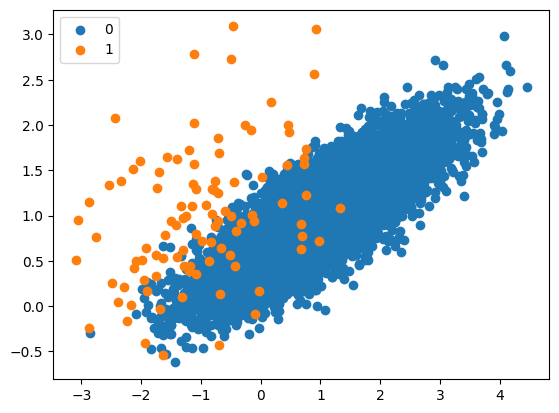

In [21]:
# Generate and plot a synthetic imbalanced classification dataset
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# summarize class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	plt.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
plt.legend()
plt.show()

In [24]:
# transform the dataset
oversample = SMOTE()
X, y = oversample.fit_resample(X, y)
# summarize the new class distribution
counter = Counter(y)
print(counter)

Counter({np.int64(0): 9900, np.int64(1): 9900})


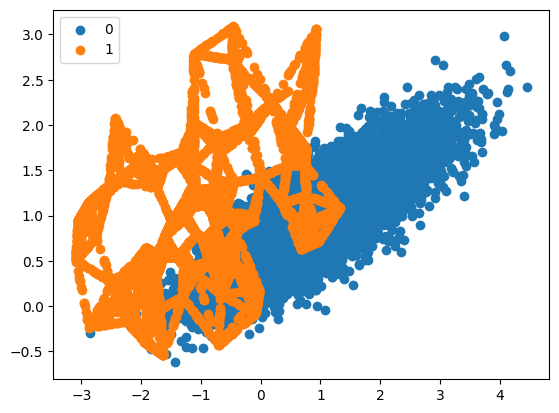

In [26]:
# scatter plot of examples by class label
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	plt.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
plt.legend()
plt.show()

# Oversampling with SMOTE and random undersampling

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 1980, np.int64(1): 990})


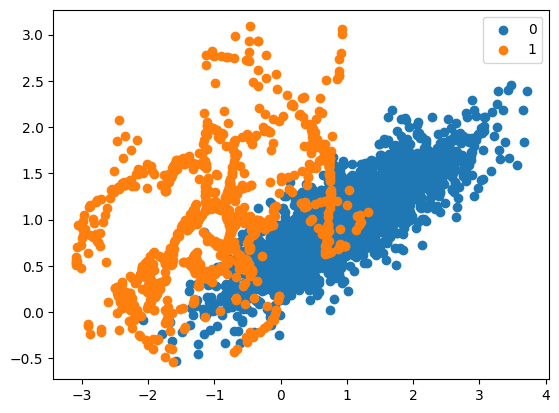

In [31]:
# Oversample with SMOTE and random undersample for imbalanced dataset
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# summarize class distribution
counter = Counter(y)
print(counter)
# define pipeline
over = SMOTE(sampling_strategy=0.1)
under = RandomUnderSampler(sampling_strategy=0.5)
steps = [('o', over), ('u', under)]
pipeline = Pipeline(steps=steps)
# transform the dataset
X, y = pipeline.fit_resample(X, y)
# summarize the new class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	plt.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
plt.legend()
plt.show()

# Decision tree evaluation for imbalanced dataset

In [40]:
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# define model
model = DecisionTreeClassifier()
# evaluate pipeline
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
scores = cross_val_score(model, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
print('Mean ROC AUC: %.3f' % np.mean(scores))

Mean ROC AUC: 0.769


In [42]:
# decision tree evaluated on imbalanced dataset with SMOTE oversampling
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# define pipeline
steps = [('over', SMOTE()), ('model', DecisionTreeClassifier())]
pipeline = Pipeline(steps=steps)
# evaluate pipeline
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
scores = cross_val_score(pipeline, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
print('Mean ROC AUC: %.3f' % np.mean(scores))

Mean ROC AUC: 0.821


In [43]:
# decision tree  on imbalanced dataset with SMOTE oversampling and random undersampling
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# define pipeline
model = DecisionTreeClassifier()
over = SMOTE(sampling_strategy=0.1)
under = RandomUnderSampler(sampling_strategy=0.5)
steps = [('over', over), ('under', under), ('model', model)]
pipeline = Pipeline(steps=steps)
# evaluate pipeline
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
scores = cross_val_score(pipeline, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
print('Mean ROC AUC: %.3f' % np.mean(scores))

Mean ROC AUC: 0.844


In [44]:
# grid search k value for SMOTE oversampling for imbalanced classification
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# values to evaluate
k_values = [1, 2, 3, 4, 5, 6, 7]
for k in k_values:
	# define pipeline
	model = DecisionTreeClassifier()
	over = SMOTE(sampling_strategy=0.1, k_neighbors=k)
	under = RandomUnderSampler(sampling_strategy=0.5)
	steps = [('over', over), ('under', under), ('model', model)]
	pipeline = Pipeline(steps=steps)
	# evaluate pipeline
	cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
	scores = cross_val_score(pipeline, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
	score = np.mean(scores)
	print('> k=%d, Mean ROC AUC: %.3f' % (k, score))

> k=1, Mean ROC AUC: 0.818
> k=2, Mean ROC AUC: 0.822
> k=3, Mean ROC AUC: 0.844
> k=4, Mean ROC AUC: 0.840
> k=5, Mean ROC AUC: 0.848
> k=6, Mean ROC AUC: 0.841
> k=7, Mean ROC AUC: 0.842
